# Do scheduled token unlocks help forecast crypto volatility?

**MH6805 group project, Group 7.** One notebook, the whole analysis pipeline. Data gathering (Tokenomist API + Binance klines) is outside the scope of this notebook; it starts from `data/dataset_v1.csv`, whose columns are documented in `data/COLUMN_GUIDE.md`.

## Question
Do scheduled token-unlock (emission) features add forecasting power for a token's **forward 14-day realized volatility** beyond volatility persistence and market regime?

Every model is run twice: on **control features only** (trailing volatility, trailing returns, BTC/ETH volatility, size, age) and on **controls + emission + static** features. The difference is the finding. A null or negative result is a valid result; nothing is tuned until it disappears.

## Data
- Panel of 176 tokens x calendar day, 2024-09-14 to 2026-08-15, one row per token-day.
- Target `y = log(rv_fwd_14d)`: annualized realized volatility of daily log returns over the next 14 days.
- Emission features come from the unlock schedule as published, so they are known in advance (the only forward-looking inputs allowed). Caveat: schedules are the version curated on the pull date, so they are lookahead-safe mechanically but not against later revisions.

## Protocol (never shuffled)
- 5 walk-forward folds, tokens pooled, cutoffs every 90 days over the last 450 days.
- train = date <= cutoff - 30 days (embargo, because the target looks ahead); test = the 90 days after the cutoff.
- The last 90 days of train are the validation slice; tuning fits on train minus validation minus a 30-day purge, picks the config with the lowest validation RMSE, refits on all of train and scores **once** on test. Tuning never touches test.
- Metrics in log-vol space: RMSE, MAE, Spearman, and `r2_oos = 1 - SSE_model / SSE_persistence` where persistence = `log(rv_past_14d)`. `r2_oos = 0` means the model ties the persistence forecast.
- Scalers and models are fit on the training slice of the current fold only (they live inside each sklearn `Pipeline`). `random_state = 42` everywhere.

## How to run
Run from the repository root with `data/dataset_v1.csv` in place (`pip install -r requirements.txt`, Python 3.13). Cells are sequential.

Model runs are expensive (the Random Forest section is ~700 fits of 400 trees, several hours on 8 cores), so each run is stored in `results/<model>.csv` (one row per fold) and **reused on the next execution**; the notebook then only refits the two interpretation models and rebuilds every table and figure (about 20 minutes). Set the environment variable `NB_FRESH=1` before starting the kernel to recompute every run from scratch, or `NB_SMOKE=1` to run tiny models as a code check (nothing is saved in that mode).

Outputs are written to `results/` (one CSV per model, one row per fold per run; test-set predictions as parquet) and `figures/` (PNG copies of every chart shown below).


## 0. Shared harness

Data cleaning, feature sets, walk-forward folds, metrics, baselines and the generic tune / refit / predict loop. This is the content of `common.py` in the repository, inlined so the notebook is self-contained.

Feature sets (names after cleaning):
- `CONTROLS` (9): `rv_past_7d/14d/30d`, `ret_past_7d/30d`, `btc_rv_past_14d`, `eth_rv_past_14d`, `log_mcap_pit`, `days_since_tge`
- `EMISSION` (13): `emis_next_{7,30,90}d_pct_float` (log1p), `emis_next_30d_pct_total`, `days_to_next_cliff` (null -> 365), `next_cliff_pct_float` (log1p, null -> 0), `has_unlock_events`, six `emis_next_30d_<recipient>_pct_float` (log1p)
- `STATIC` (10): six `alloc_share_<recipient>`, `listedMethod` one-hots, `unlockPrecision_ord`
- `FULL` = CONTROLS + EMISSION + STATIC (32); `CONTROLS+EMIS5` adds the five headline emission columns only.


In [1]:
# ---- imports ----------------------------------------------------------------
import json
import os
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Image, display
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Patch
from scipy.stats import spearmanr
from lightgbm import LGBMRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.inspection import partial_dependence, permutation_importance
from sklearn.linear_model import ElasticNet, Ridge
from sklearn.neighbors import KNeighborsRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import QuantileTransformer, StandardScaler

%matplotlib inline
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)

# NB_SMOKE=1 runs tiny models and saves nothing (code check only).
SMOKE = os.environ.get("NB_SMOKE") == "1"
print("python", sys.version.split()[0], "| SMOKE =", SMOKE)

# ---- shared harness (identical to common.py in the repository) ----------------
import itertools
import json
import time
from pathlib import Path

import numpy as np
import pandas as pd
from scipy.stats import spearmanr

RANDOM_STATE = 42

ROOT = Path.cwd()   # run from the repo root
DATA_PATH = ROOT / "data" / "dataset_v1.csv"
RESULTS_DIR = ROOT / "results"
FIGURES_DIR = ROOT / "figures"

# --------------------------------------------------------------------------
# Column bookkeeping
# --------------------------------------------------------------------------
BUCKETS = ["founderTeam", "privateInvestors", "community",
           "publicInvestors", "reserve", "others"]

RAW_TARGETS = ["rv_fwd_7d", "rv_fwd_14d", "rv_fwd_30d",
               "rv_fwd_14d_parkinson", "fwd_ret_14d"]

# cleaned target column -> tag written to the `target` column of results CSVs
TARGETS = {
    "y": "log_rv_fwd_14d",
    "y_7d": "log_rv_fwd_7d",
    "y_30d": "log_rv_fwd_30d",
    "y_14d_parkinson": "log_rv_fwd_14d_parkinson",
}
_TARGET_SOURCE = {
    "y": "rv_fwd_14d",
    "y_7d": "rv_fwd_7d",
    "y_30d": "rv_fwd_30d",
    "y_14d_parkinson": "rv_fwd_14d_parkinson",
}

# persistence benchmark used in r2_oos, for every target
PERSIST_COL = "rv_past_14d"

LISTED_METHODS = ["INTERNAL", "AI", "EXTERNAL"]
PRECISION_ORDER = ["second", "hour", "block", "day", "week", "month", "unknown"]

RAW_EMIS_COUNT_COLS = (["emis_next_7d", "emis_next_30d", "emis_next_90d"]
                       + [f"emis_next_30d_{b}" for b in BUCKETS]
                       + ["emis_next_30d_unattributed"])
DROP_COLS = (["symbol", "tge_proxy_date", "total_supply_basis", "total_supply",
              "float_pit", "listedMethod", "unlockPrecision"]
             + RAW_EMIS_COUNT_COLS + RAW_TARGETS)

# --------------------------------------------------------------------------
# Feature sets (names are the column names AFTER load_data cleaning)
# --------------------------------------------------------------------------
CONTROLS = ["rv_past_7d", "rv_past_14d", "rv_past_30d", "ret_past_7d",
            "ret_past_30d", "btc_rv_past_14d", "eth_rv_past_14d",
            "log_mcap_pit", "days_since_tge"]

EMISSION_BUCKETS = [f"emis_next_30d_{b}_pct_float" for b in BUCKETS]
EMISSION = (["emis_next_7d_pct_float", "emis_next_30d_pct_float",
             "emis_next_90d_pct_float", "emis_next_30d_pct_total",
             "days_to_next_cliff", "next_cliff_pct_float", "has_unlock_events"]
            + EMISSION_BUCKETS)

STATIC = ([f"alloc_share_{b}" for b in BUCKETS]
          + [f"listedMethod_{m}" for m in LISTED_METHODS]
          + ["unlockPrecision_ord"])

FULL = CONTROLS + EMISSION + STATIC

EMIS5 = ["emis_next_30d_pct_float", "emis_next_7d_pct_float",
         "next_cliff_pct_float", "days_to_next_cliff", "has_unlock_events"]

FEATURE_SETS: dict[str, list[str]] = {
    "CONTROLS": CONTROLS,
    "EMISSION": EMISSION,
    "STATIC": STATIC,
    "FULL": FULL,
    "CONTROLS+EMIS5": CONTROLS + EMIS5,
    # recipient-split variant: the six bucket columns carry the 30d signal
    "FULL_NO_AGG30": [c for c in FULL if c != "emis_next_30d_pct_float"],
}


def register_feature_set(name: str, columns: list[str]) -> None:
    """Add a named feature set so run_model can look it up."""
    missing = [c for c in columns if c not in _cleaned_columns()]
    if missing:
        raise KeyError(f"feature set {name!r}: unknown columns {missing}")
    FEATURE_SETS[name] = list(columns)


def _cleaned_columns(path: Path = DATA_PATH) -> set[str]:
    """Column names load_data will produce, derived from the CSV header only."""
    raw = list(pd.read_csv(path, nrows=0).columns)
    cols = [c for c in raw if c not in DROP_COLS]
    cols += list(TARGETS)
    cols += EMISSION_BUCKETS
    cols += [f"listedMethod_{m}" for m in LISTED_METHODS]
    cols += ["unlockPrecision_ord"]
    return set(cols)


def _verify_feature_sets() -> None:
    have = _cleaned_columns()
    for name, cols in FEATURE_SETS.items():
        missing = [c for c in cols if c not in have]
        if missing:
            raise KeyError(f"feature set {name}: columns missing from "
                           f"{DATA_PATH.name} after cleaning: {missing}")
        dupes = {c for c in cols if cols.count(c) > 1}
        if dupes:
            raise ValueError(f"feature set {name}: duplicated columns {dupes}")
        leaked = [c for c in cols if c in RAW_TARGETS or c in TARGETS]
        if leaked:
            raise ValueError(f"feature set {name} contains targets: {leaked}")


_verify_feature_sets()


# --------------------------------------------------------------------------
# Data loading
# --------------------------------------------------------------------------
def load_data(path=DATA_PATH, freq: str = "daily", verbose: bool = True) -> pd.DataFrame:
    """Load and clean the panel. Returns token_id, date, targets and features,
    sorted by (token_id, date) with a fresh 0..n-1 index. Never shuffled."""
    if freq not in ("daily", "weekly"):
        raise ValueError("freq must be 'daily' or 'weekly'")

    def log(step, before, after):
        if verbose:
            print(f"[load_data] {step:<44s} rows {before:>7,d} -> {after:>7,d}")

    df = pd.read_csv(path)
    n0 = len(df)

    # 1. parse date, sort
    df["date"] = pd.to_datetime(df["date"])
    df = df.sort_values(["token_id", "date"], kind="stable").reset_index(drop=True)
    log("1 parse date, sort (token_id, date)", n0, len(df))

    # 2. drop rows without target / 30d history
    n = len(df)
    df = df[df["rv_fwd_14d"].notna() & df["rv_past_30d"].notna()].copy()
    log("2 drop null rv_fwd_14d / rv_past_30d", n, len(df))

    # 3. log targets
    for new, src in _TARGET_SOURCE.items():
        df[new] = np.log(df[src])

    # 4. log1p the long-tailed pct_float columns (nulls stay null until step 5)
    pct_float_cols = [c for c in df.columns
                      if c.startswith("emis_next_") and c.endswith("_pct_float")]
    for c in pct_float_cols + ["next_cliff_pct_float"]:
        df[c] = np.log1p(df[c])

    # 5. structural nulls (tokens without cliffs / no cliff left in window)
    df["days_to_next_cliff"] = df["days_to_next_cliff"].fillna(365)
    df["next_cliff_pct_float"] = df["next_cliff_pct_float"].fillna(0.0)

    # 6. recipient buckets as share of float, log1p
    for b in BUCKETS:
        df[f"emis_next_30d_{b}_pct_float"] = np.log1p(
            df[f"emis_next_30d_{b}"] / df["float_pit"])

    # 7. encodings with fixed category lists (nothing is learned from data)
    unknown_lm = set(df["listedMethod"].dropna().unique()) - set(LISTED_METHODS)
    if unknown_lm:
        raise ValueError(f"unexpected listedMethod values: {unknown_lm}")
    for m in LISTED_METHODS:
        df[f"listedMethod_{m}"] = (df["listedMethod"] == m).astype(int)
    prec = df["unlockPrecision"].fillna("unknown")
    unknown_p = set(prec.unique()) - set(PRECISION_ORDER)
    if unknown_p:
        raise ValueError(f"unexpected unlockPrecision values: {unknown_p}")
    df["unlockPrecision_ord"] = prec.map(
        {p: i for i, p in enumerate(PRECISION_ORDER)}).astype(int)
    for c in ["has_unlock_events", "emission_schedule_ended"]:
        df[c] = df[c].astype(int)

    # 8. drop identifiers, raw token counts and every raw target
    df = df.drop(columns=[c for c in DROP_COLS if c in df.columns])

    # 9. weekly: first available day of each ISO week per token
    if freq == "weekly":
        n = len(df)
        iso = df["date"].dt.isocalendar()
        df = (df.assign(_y=iso["year"].values, _w=iso["week"].values)
                .groupby(["token_id", "_y", "_w"], sort=False, as_index=False)
                .head(1)
                .drop(columns=["_y", "_w"]))
        log("9 weekly: first day of ISO week per token", n, len(df))

    df = df.sort_values(["token_id", "date"], kind="stable").reset_index(drop=True)

    nulls = df[FULL + list(TARGETS)].isna().sum()
    if nulls.any():
        raise ValueError(f"nulls remain after cleaning:\n{nulls[nulls > 0]}")

    lead = ["token_id", "date"] + list(TARGETS)
    df = df[lead + [c for c in df.columns if c not in lead]]
    if verbose:
        print(f"[load_data] freq={freq}: {len(df):,d} rows, "
              f"{df['token_id'].nunique()} tokens, "
              f"{df['date'].min().date()} .. {df['date'].max().date()}")
    return df


# --------------------------------------------------------------------------
# Walk-forward folds
# --------------------------------------------------------------------------
def make_folds(df: pd.DataFrame, n_folds: int = 5, test_days: int = 90,
               embargo_days: int = 30, val_days: int = 90, verbose: bool = True):
    """Walk-forward folds by date, all tokens pooled.

    Returns a list of (train_idx, val_idx, test_idx) positional index arrays.
    val_idx is the last `val_days` of train and is a subset of train_idx.
    Cutoff dates are stored on the returned list as `.cutoffs`.
    """
    dates = df["date"].to_numpy()
    max_date = df["date"].max()
    day = pd.Timedelta(days=1)
    folds = FoldList()
    for i in range(n_folds):
        c = max_date - (n_folds - i) * test_days * day
        train_end = c - embargo_days * day
        val_start = train_end - val_days * day  # val = (val_start, train_end]
        train_mask = dates <= train_end.to_datetime64()
        val_mask = train_mask & (dates > val_start.to_datetime64())
        test_mask = (dates > c.to_datetime64()) & \
                    (dates <= (c + test_days * day).to_datetime64())
        tr, va, te = (np.flatnonzero(m) for m in (train_mask, val_mask, test_mask))
        if min(len(tr) - len(va), len(va), len(te)) <= 0:
            raise ValueError(f"fold {i + 1} has an empty slice; "
                             "reduce n_folds/test_days/val_days")

        # no test row within embargo_days after any train row
        gap = (dates[te].min() - dates[tr].max()) / np.timedelta64(1, "D")
        assert gap > embargo_days, f"fold {i + 1}: embargo violated (gap {gap}d)"
        assert not np.intersect1d(tr, te).size
        assert np.isin(va, tr).all()

        folds.append((tr, va, te))
        folds.cutoffs.append(c)
        if verbose:
            d = lambda ix: f"{pd.Timestamp(dates[ix].min()).date()}..{pd.Timestamp(dates[ix].max()).date()}"
            print(f"[make_folds] fold {i + 1} cutoff {c.date()} | "
                  f"train {len(tr):>6,d} {d(tr)} | "
                  f"val {len(va):>6,d} {d(va)} | "
                  f"test {len(te):>6,d} {d(te)}")
    return folds


class FoldList(list):
    """A list of (train_idx, val_idx, test_idx) that also carries cutoff dates."""

    def __init__(self, *args):
        super().__init__(*args)
        self.cutoffs: list[pd.Timestamp] = []


def fit_slice(df: pd.DataFrame, train_idx, val_idx, purge_days: int = 30):
    """Rows of train used to fit during tuning: train minus val, minus the
    `purge_days` right before val (their forward targets overlap the val
    period, which would flatter low-bias models such as small-k KNN)."""
    dates = df["date"].to_numpy()
    val_start = dates[val_idx].min()
    keep = dates[train_idx] <= val_start - np.timedelta64(purge_days + 1, "D")
    return np.asarray(train_idx)[keep]


# --------------------------------------------------------------------------
# Metrics and baselines
# --------------------------------------------------------------------------
def evaluate(y_true, y_pred, y_persist) -> dict:
    """Metrics in log-vol space. r2_oos is relative to the persistence
    forecast (y_persist = log rv_past_14d): 0 = ties persistence."""
    y_true, y_pred, y_persist = (np.asarray(a, dtype=float)
                                 for a in (y_true, y_pred, y_persist))
    err = y_true - y_pred
    sse = float(np.sum(err ** 2))
    sse_p = float(np.sum((y_true - y_persist) ** 2))
    rho = spearmanr(y_true, y_pred).statistic if np.ptp(y_pred) > 0 else np.nan
    return {
        "rmse": float(np.sqrt(np.mean(err ** 2))),
        "mae": float(np.mean(np.abs(err))),
        "r2_oos": 1.0 - sse / sse_p,
        "spearman": float(rho),
        "rmse_level": float(np.sqrt(np.mean((np.exp(y_true) - np.exp(y_pred)) ** 2))),
        "n": int(len(y_true)),
    }


RESULT_COLUMNS = ["model", "feature_set", "freq", "target", "fold", "cutoff_date",
                  "n_train", "n_test", "best_params", "rmse", "mae", "r2_oos",
                  "spearman", "rmse_level", "subsample"]
RUN_KEY = ["model", "feature_set", "freq", "target", "subsample"]


def _upsert_results(path: Path, new: pd.DataFrame) -> None:
    """Append to a results CSV, replacing rows from an earlier identical run."""
    path.parent.mkdir(parents=True, exist_ok=True)
    if path.exists():
        old = pd.read_csv(path)
        if "subsample" not in old.columns:
            old["subsample"] = "all"
        keys = set(map(tuple, new[RUN_KEY].astype(str).drop_duplicates().to_numpy()))
        keep = [tuple(r) not in keys for r in old[RUN_KEY].astype(str).to_numpy()]
        new = pd.concat([old[keep], new], ignore_index=True)
    new[RESULT_COLUMNS].to_csv(path, index=False)


def baselines(df: pd.DataFrame, folds, freq: str = "daily", target: str = "y",
              subsample: str = "all", save: bool = True) -> pd.DataFrame:
    """Persistence (log rv_past_14d) and pooled train-mean forecasts per fold."""
    y = df[target].to_numpy()
    persist = np.log(df[PERSIST_COL].to_numpy())
    rows = []
    for k, (tr, _, te) in enumerate(folds, start=1):
        preds = {"persistence": persist[te],
                 "train_mean": np.full(len(te), y[tr].mean())}
        for name, p in preds.items():
            m = evaluate(y[te], p, persist[te])
            rows.append({"model": name, "feature_set": "NONE", "freq": freq,
                         "target": TARGETS[target], "fold": k,
                         "cutoff_date": folds.cutoffs[k - 1].date().isoformat(),
                         "n_train": len(tr), "n_test": m.pop("n"),
                         "best_params": "{}", **m, "subsample": subsample})
    out = pd.DataFrame(rows)[RESULT_COLUMNS]
    if save:
        _upsert_results(RESULTS_DIR / "baselines.csv", out)
    return out


# --------------------------------------------------------------------------
# Generic model loop
# --------------------------------------------------------------------------
def expand_grid(param_grid: dict, max_configs: int | None = None) -> list[dict]:
    """All combinations of param_grid; optionally a fixed random subset."""
    keys = list(param_grid)
    configs = [dict(zip(keys, v)) for v in itertools.product(*param_grid.values())]
    if max_configs is not None and max_configs < len(configs):
        rng = np.random.default_rng(RANDOM_STATE)
        pick = sorted(rng.choice(len(configs), size=max_configs, replace=False))
        configs = [configs[i] for i in pick]
    return configs


def _jsonable(params: dict) -> str:
    return json.dumps({k: (v.item() if isinstance(v, np.generic) else v)
                       for k, v in params.items()}, sort_keys=True)


def run_tag(feature_set_name, freq, target="y", subsample="all") -> str:
    tag = f"{feature_set_name}_{freq}"
    if target != "y":
        tag += f"_{TARGETS[target]}"
    if subsample != "all":
        tag += f"_{subsample}"
    return tag


def run_model(name, estimator_factory, df, folds, feature_set_name, param_grid,
              freq, *, target: str = "y", subsample: str = "all",
              max_configs: int | None = None, purge_days: int = 30,
              save: bool = True, verbose: bool = True) -> pd.DataFrame:
    """Tune on the validation slice, refit on full train, score on test.

    estimator_factory(**params) must return an unfitted sklearn Pipeline (or
    estimator); any scaler inside it is therefore fit on training rows only.
    param_grid is {param_name: [values]}; max_configs evaluates a fixed random
    subset of the grid (seeded) when the full grid is too slow.
    `df` must be the frame `folds` was built from. `subsample` is only a label
    for the results CSV -- filter df yourself before calling make_folds.

    Writes results/<name>.csv, results/preds_<name>_<tag>.parquet and
    results/val_<name>_<tag>.csv (validation RMSE of every config tried).
    """
    features = FEATURE_SETS[feature_set_name]
    if target not in TARGETS:
        raise KeyError(f"target must be one of {list(TARGETS)}")
    X = df[features].to_numpy(dtype=float)
    y = df[target].to_numpy()
    persist = np.log(df[PERSIST_COL].to_numpy())
    configs = expand_grid(param_grid, max_configs)
    tag = run_tag(feature_set_name, freq, target, subsample)

    rows, preds, val_rows = [], [], []
    t_start = time.perf_counter()
    for k, (tr, va, te) in enumerate(folds, start=1):
        t0 = time.perf_counter()
        fit = fit_slice(df, tr, va, purge_days)
        best = (np.inf, None)
        for params in configs:
            est = estimator_factory(**params).fit(X[fit], y[fit])
            rmse = float(np.sqrt(np.mean((y[va] - est.predict(X[va])) ** 2)))
            val_rows.append({"model": name, "feature_set": feature_set_name,
                             "freq": freq, "target": TARGETS[target],
                             "subsample": subsample, "fold": k, **params,
                             "val_rmse": rmse})
            if rmse < best[0]:
                best = (rmse, params)
        est = estimator_factory(**best[1]).fit(X[tr], y[tr])
        p = est.predict(X[te])
        m = evaluate(y[te], p, persist[te])
        rows.append({"model": name, "feature_set": feature_set_name, "freq": freq,
                     "target": TARGETS[target], "fold": k,
                     "cutoff_date": folds.cutoffs[k - 1].date().isoformat(),
                     "n_train": len(tr), "n_test": m.pop("n"),
                     "best_params": _jsonable(best[1]), **m,
                     "subsample": subsample})
        preds.append(pd.DataFrame({"token_id": df["token_id"].to_numpy()[te],
                                   "date": df["date"].to_numpy()[te],
                                   "y_true": y[te], "y_pred": p, "fold": k}))
        if verbose:
            print(f"[{name}|{tag}] fold {k}: val_rmse {best[0]:.4f} "
                  f"test rmse {m['rmse']:.4f} r2_oos {m['r2_oos']:+.4f} "
                  f"best {_jsonable(best[1])} ({time.perf_counter() - t0:.1f}s)")

    out = pd.DataFrame(rows)[RESULT_COLUMNS]
    if verbose:
        print(f"[{name}|{tag}] mean r2_oos {out['r2_oos'].mean():+.4f} "
              f"mean rmse {out['rmse'].mean():.4f} "
              f"({len(configs)} configs, {time.perf_counter() - t_start:.1f}s total)")
    if save:
        _upsert_results(RESULTS_DIR / f"{name}.csv", out)
        pd.concat(preds, ignore_index=True).to_parquet(
            RESULTS_DIR / f"preds_{name}_{tag}.parquet", index=False)
        pd.DataFrame(val_rows).to_csv(
            RESULTS_DIR / f"val_{name}_{tag}.csv", index=False)
    return out


# --------------------------------------------------------------------------
# Fixed log transform for the linear models (Ridge / Elastic Net)
# --------------------------------------------------------------------------
# Volatility levels and token age are right-skewed and enter a linear model
# better in logs. Nothing is learned from data, so it is safe in any fold.
LOG_COLS = ["rv_past_7d", "rv_past_14d", "rv_past_30d",
            "btc_rv_past_14d", "eth_rv_past_14d"]
LOG1P_COLS = ["days_since_tge"]


def _log_columns(X, ix_log=(), ix_log1p=()):
    X = np.array(X, dtype=float, copy=True)
    X[:, list(ix_log)] = np.log(X[:, list(ix_log)])
    X[:, list(ix_log1p)] = np.log1p(X[:, list(ix_log1p)])
    return X


def log_transformer(features: list[str]):
    """FunctionTransformer that logs LOG_COLS and log1ps LOG1P_COLS, located
    by position in `features` (the column order of the feature matrix)."""
    from sklearn.preprocessing import FunctionTransformer
    return FunctionTransformer(_log_columns, kw_args={
        "ix_log": [i for i, f in enumerate(features) if f in LOG_COLS],
        "ix_log1p": [i for i, f in enumerate(features) if f in LOG1P_COLS]})


# --------------------------------------------------------------------------
# Plot style shared by all scripts
# --------------------------------------------------------------------------
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#4a3aa7", "#e34948"]
INK, INK_2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"


def set_style() -> None:
    from cycler import cycler
    plt.rcParams.update({
        "figure.dpi": 100, "savefig.dpi": 150, "savefig.bbox": "tight",
        "figure.facecolor": SURFACE, "axes.facecolor": SURFACE,
        "savefig.facecolor": SURFACE,
        "axes.prop_cycle": cycler(color=PALETTE),
        "axes.edgecolor": GRID, "axes.labelcolor": INK_2,
        "axes.titlecolor": INK, "axes.titlesize": 12, "axes.titleweight": "bold",
        "axes.titlelocation": "left", "axes.labelsize": 10,
        "axes.spines.top": False, "axes.spines.right": False,
        "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
        "axes.axisbelow": True,
        "xtick.color": INK_2, "ytick.color": INK_2,
        "xtick.labelsize": 9, "ytick.labelsize": 9,
        "text.color": INK, "legend.frameon": False, "legend.fontsize": 9,
        "lines.linewidth": 2, "lines.markersize": 6, "font.size": 10,
    })


def savefig(fig, name: str) -> Path:
    FIGURES_DIR.mkdir(parents=True, exist_ok=True)
    path = FIGURES_DIR / name
    fig.savefig(path, dpi=150)
    display(fig)          # show inline in the notebook ...
    plt.close(fig)        # ... and save a PNG copy under figures/
    print(f"[figure] {path.relative_to(ROOT)}")
    return path




# ---- resume support -------------------------------------------------------------
# Every model run is ~5-45 min (Random Forest) and results/<model>.csv keeps one row
# per fold per run, so a finished run is reused instead of recomputed. Set
# FRESH = True (or delete the CSV) to recompute everything from scratch.
FRESH = os.environ.get("NB_FRESH") == "1"


def finished_run(model, folds, fs, freq, target="y", subsample="all"):
    """Rows already in results/<model>.csv for this run, or None if incomplete."""
    path = RESULTS_DIR / f"{model}.csv"
    if SMOKE or FRESH or not path.exists():
        return None
    old = pd.read_csv(path)
    key = {"model": model, "feature_set": fs, "freq": freq,
           "target": TARGETS[target], "subsample": subsample}
    mask = np.logical_and.reduce([old[k].astype(str) == v for k, v in key.items()])
    rows = old[mask]
    if len(rows) == len(folds) and sorted(rows["fold"]) == list(range(1, len(folds) + 1)):
        print(f"[{model}|{run_tag(fs, freq, target, subsample)}] found in results/{model}.csv, "
              f"reusing (mean rmse {rows['rmse'].mean():.4f}, r2_oos {rows['r2_oos'].mean():+.4f}); "
              "set NB_FRESH=1 to recompute")
        return rows.reset_index(drop=True)
    return None


python 3.13.1 | SMOKE = False


## 1. Load and clean the panel

`load_data` parses dates, sorts by (token, date), drops rows without a target or 30 days of price history, takes logs of the targets and of the long-tailed emission ratios, fills the two structurally-null cliff columns, encodes the categorical columns with fixed category lists (nothing is learned from the data), and drops identifiers, raw token counts and every raw target so none can leak into a feature matrix. The weekly panel keeps the first available day of each ISO week per token.


In [2]:
daily = load_data(freq="daily")
weekly = load_data(freq="weekly")
display(daily.head())
display(daily[["y"] + CONTROLS + EMIS5].describe().T.round(4))

[load_data] 1 parse date, sort (token_id, date)          rows 103,685 -> 103,685
[load_data] 2 drop null rv_fwd_14d / rv_past_30d         rows 103,685 -> 101,393


[load_data] freq=daily: 101,393 rows, 176 tokens, 2024-09-14 .. 2026-08-15


[load_data] 1 parse date, sort (token_id, date)          rows 103,685 -> 103,685
[load_data] 2 drop null rv_fwd_14d / rv_past_30d         rows 103,685 -> 101,393


[load_data] 9 weekly: first day of ISO week per token    rows 101,393 ->  14,623
[load_data] freq=weekly: 14,623 rows, 176 tokens, 2024-09-14 .. 2026-08-10


,token_id,date,y,y_7d,y_30d,y_14d_parkinson,emis_next_7d_pct_float,emis_next_30d_pct_float,emis_next_90d_pct_float,emis_next_30d_pct_total,days_to_next_cliff,next_cliff_pct_float,has_unlock_events,emission_schedule_ended,rv_past_7d,rv_past_14d,rv_past_30d,ret_past_7d,ret_past_30d,btc_rv_past_14d,eth_rv_past_14d,log_mcap_pit,days_since_tge,alloc_share_founderTeam,alloc_share_privateInvestors,alloc_share_community,alloc_share_publicInvestors,alloc_share_reserve,alloc_share_others,emis_next_30d_founderTeam_pct_float,emis_next_30d_privateInvestors_pct_float,emis_next_30d_community_pct_float,emis_next_30d_publicInvestors_pct_float,emis_next_30d_reserve_pct_float,emis_next_30d_others_pct_float,listedMethod_INTERNAL,listedMethod_AI,listedMethod_EXTERNAL,unlockPrecision_ord
0,1inch,2024-09-14,-0.275819,-0.101115,-0.325925,-0.240520,0.000042,0.000468,0.074618,0.000401,7.0,0.000042,1,0,0.644160,1.373570,1.049798,0.043273,0.060148,0.483368,0.595005,19.635867,1359,0.0,0.0,0.070242,0.0,0.0,0.929758,0.0,0.0,0.0,0.0,0.0,0.000468,1,0,0,0
1,1inch,2024-09-15,-0.376033,-0.166276,-0.372530,-0.253127,0.000042,0.000468,0.074618,0.000401,6.0,0.000042,1,0,0.797116,1.380109,1.071737,-0.021749,0.015180,0.466394,0.607934,19.570845,1360,0.0,0.0,0.070242,0.0,0.0,0.929758,0.0,0.0,0.0,0.0,0.0,0.000468,1,0,0,0
2,1inch,2024-09-16,-0.298931,-0.203187,-0.385366,-0.225519,0.000042,0.000468,0.074618,0.000401,5.0,0.000042,1,0,0.779862,1.379320,1.080700,-0.108366,-0.031298,0.445121,0.564128,19.530549,1361,0.0,0.0,0.070242,0.0,0.0,0.929758,0.0,0.0,0.0,0.0,0.0,0.000468,1,0,0,0
3,1inch,2024-09-17,-0.167452,-0.173205,-0.375722,-0.083080,0.000042,0.000468,0.074618,0.000401,4.0,0.000042,1,0,0.784273,1.354581,1.081791,-0.081293,-0.007481,0.458408,0.524165,19.546529,1362,0.0,0.0,0.070242,0.0,0.0,0.929758,0.0,0.0,0.0,0.0,0.0,0.000468,1,0,0,0
4,1inch,2024-09-18,-0.217194,-0.296890,-0.401649,-0.084404,0.000042,0.000468,0.074618,0.000401,3.0,0.000042,1,0,0.803143,0.808367,1.089025,0.022769,0.005942,0.472171,0.526312,19.601321,1363,0.0,0.0,0.070242,0.0,0.0,0.929758,0.0,0.0,0.0,0.0,0.0,0.000468,1,0,0,0


,count,mean,std,min,25%,50%,75%,max
y,101393.0,-0.1018,0.4382,-2.0691,-0.3835,-0.1121,0.1697,2.1725
rv_past_7d,101393.0,0.9621,0.5761,0.0774,0.6103,0.8358,1.1571,12.2414
rv_past_14d,101393.0,1.0024,0.5027,0.1263,0.6847,0.8976,1.1901,8.7802
rv_past_30d,101393.0,1.0430,0.4281,0.1762,0.7614,0.9702,1.2229,6.0603
ret_past_7d,101393.0,-0.0232,0.1439,-1.1322,-0.1051,-0.0244,0.0523,1.7109
ret_past_30d,101393.0,-0.1026,0.2920,-2.3675,-0.2868,-0.1046,0.0574,1.8152
btc_rv_past_14d,101393.0,0.4038,0.1665,0.1362,0.3063,0.3727,0.4584,1.1292
eth_rv_past_14d,101393.0,0.6364,0.2415,0.2031,0.4676,0.6000,0.7452,1.3780
log_mcap_pit,101393.0,19.0527,1.8458,15.1462,17.6507,18.7950,20.2359,25.7918
days_since_tge,101393.0,916.8488,676.4447,30.0000,350.0000,701.0000,1469.0000,3167.0000


## 2. Walk-forward folds

Five folds by calendar date with all tokens pooled. The printout shows, per fold, the cutoff and the date ranges of train, validation (last 90 days of train) and test (90 days after the cutoff, separated from train by a 30-day embargo).


In [3]:
folds_daily = make_folds(daily)
folds_weekly = make_folds(weekly)
data = {"daily": (daily, folds_daily), "weekly": (weekly, folds_weekly)}
set_style()

[make_folds] fold 1 cutoff 2025-05-22 | train 24,122 2024-09-14..2025-04-22 | val 10,577 2025-01-23..2025-04-22 | test 12,730 2025-05-23..2025-08-20


[make_folds] fold 2 cutoff 2025-08-20 | train 36,322 2024-09-14..2025-07-21 | val 12,200 2025-04-23..2025-07-21 | test 13,880 2025-08-21..2025-11-18
[make_folds] fold 3 cutoff 2025-11-18 | train 49,730 2024-09-14..2025-10-19 | val 13,408 2025-07-22..2025-10-19 | test 15,248 2025-11-19..2026-02-16
[make_folds] fold 4 cutoff 2026-02-16 | train 64,731 2024-09-14..2026-01-17 | val 15,001 2025-10-20..2026-01-17 | test 15,716 2026-02-17..2026-05-17
[make_folds] fold 5 cutoff 2026-05-17 | train 80,273 2024-09-14..2026-04-17 | val 15,542 2026-01-18..2026-04-17 | test 15,840 2026-05-18..2026-08-15
[make_folds] fold 1 cutoff 2025-05-17 | train  3,497 2024-09-14..2025-04-17 | val  1,532 2025-01-20..2025-04-17 | test  1,839 2025-05-19..2025-08-11
[make_folds] fold 2 cutoff 2025-08-15 | train  5,264 2024-09-14..2025-07-14 | val  1,767 2025-04-21..2025-07-14 | test  2,007 2025-08-18..2025-11-12
[make_folds] fold 3 cutoff 2025-11-13 | train  7,205 2024-09-14..2025-10-13 | val  1,941 2025-07-17..2025-

## 3. Exploratory data analysis

Distribution of the target and the main emission feature, forward volatility by decile of unlock pressure, Spearman correlations between target, controls and emission features, and per-token coverage against the fold cutoffs.


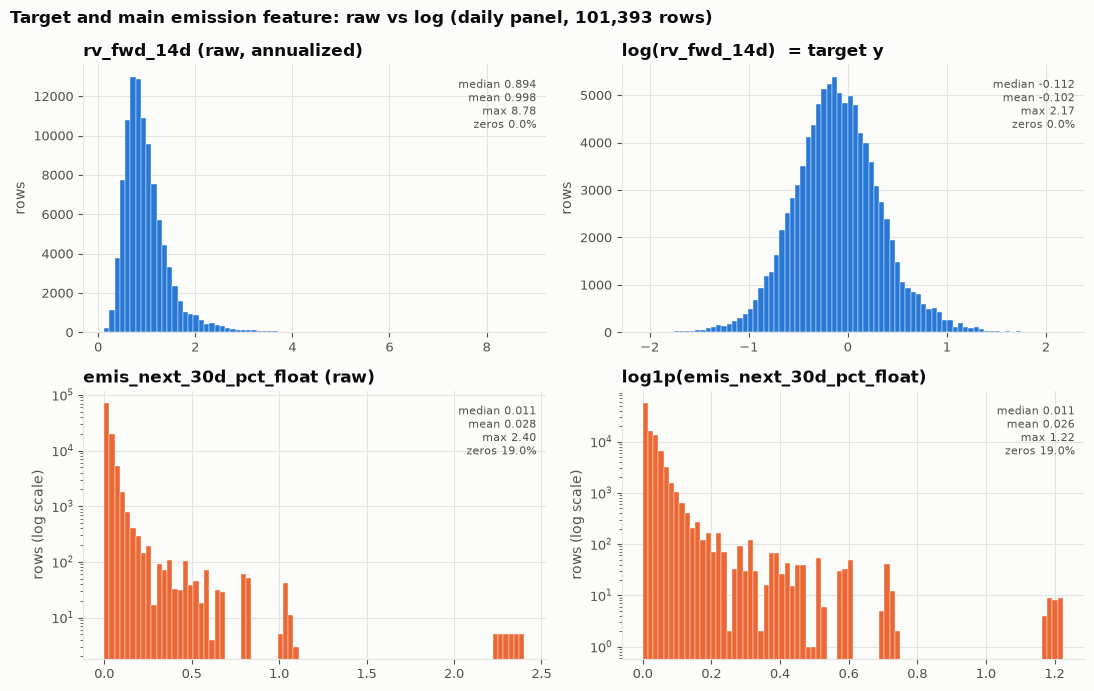

[figure] figures\eda_histograms.png


WindowsPath('D:/ML-project/figures/eda_histograms.png')

In [4]:
rv = np.exp(daily["y"])                                # rv_fwd_14d, level
emis = np.expm1(daily["emis_next_30d_pct_float"])      # raw fraction of float

# ---- 1. histograms, raw and log ------------------------------------------
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
panels = [
    (rv, "rv_fwd_14d (raw, annualized)", PALETTE[0]),
    (daily["y"], "log(rv_fwd_14d)  = target y", PALETTE[0]),
    (emis, "emis_next_30d_pct_float (raw)", PALETTE[1]),
    (daily["emis_next_30d_pct_float"], "log1p(emis_next_30d_pct_float)", PALETTE[1]),
]
for ax, (s, label, color) in zip(axes.ravel(), panels):
    ax.hist(s, bins=80, color=color, edgecolor=SURFACE, linewidth=0.3)
    ax.set_title(label)
    ax.set_ylabel("rows")
    ax.text(0.98, 0.95, f"median {s.median():.3f}\nmean {s.mean():.3f}\n"
            f"max {s.max():.2f}\nzeros {(s == 0).mean():.1%}",
            transform=ax.transAxes, ha="right", va="top", fontsize=8, color=INK_2)
axes[1, 0].set_yscale("log")
axes[1, 1].set_yscale("log")
axes[1, 0].set_ylabel("rows (log scale)")
axes[1, 1].set_ylabel("rows (log scale)")
fig.suptitle("Target and main emission feature: raw vs log (daily panel, "
             f"{len(daily):,d} rows)", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
savefig(fig, "eda_histograms.png")


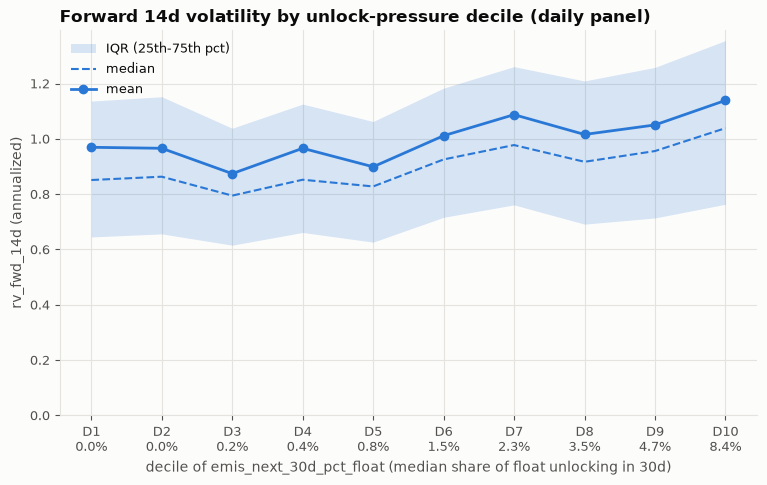

[figure] figures\eda_decile_emission_vs_rv.png
          mean  median     q25     q75  emis_median
decile                                             
1       0.9695  0.8512  0.6453  1.1366       0.0000
2       0.9659  0.8632  0.6564  1.1523       0.0000
3       0.8743  0.7948  0.6155  1.0384       0.0022
4       0.9659  0.8523  0.6616  1.1257       0.0040
5       0.8990  0.8279  0.6265  1.0627       0.0078
6       1.0114  0.9256  0.7163  1.1835       0.0149
7       1.0876  0.9776  0.7613  1.2611       0.0232
8       1.0159  0.9171  0.6917  1.2094       0.0347
9       1.0503  0.9559  0.7140  1.2584       0.0471
10      1.1390  1.0387  0.7635  1.3554       0.0842


In [5]:
# ---- 2. decile plot -------------------------------------------------------
dec = pd.qcut(emis.rank(method="first"), 10, labels=False) + 1
g = pd.DataFrame({"decile": dec, "rv": rv, "emis": emis}).groupby("decile")
stats = g["rv"].agg(mean="mean", median="median",
                    q25=lambda s: s.quantile(0.25), q75=lambda s: s.quantile(0.75))
stats["emis_median"] = g["emis"].median()
fig, ax = plt.subplots(figsize=(9, 5))
ax.fill_between(stats.index, stats["q25"], stats["q75"], color=PALETTE[0],
                alpha=0.18, linewidth=0, label="IQR (25th-75th pct)")
ax.plot(stats.index, stats["median"], color=PALETTE[0], linestyle="--",
        linewidth=1.5, label="median")
ax.plot(stats.index, stats["mean"], color=PALETTE[0], marker="o", label="mean")
ax.set_xticks(stats.index)
ax.set_xticklabels([f"D{d}\n{m:.1%}" for d, m in stats["emis_median"].items()])
ax.set_xlabel("decile of emis_next_30d_pct_float (median share of float unlocking in 30d)")
ax.set_ylabel("rv_fwd_14d (annualized)")
ax.set_ylim(0, None)
ax.set_title("Forward 14d volatility by unlock-pressure decile (daily panel)")
ax.legend(loc="upper left")
savefig(fig, "eda_decile_emission_vs_rv.png")
print(stats.round(4).to_string())


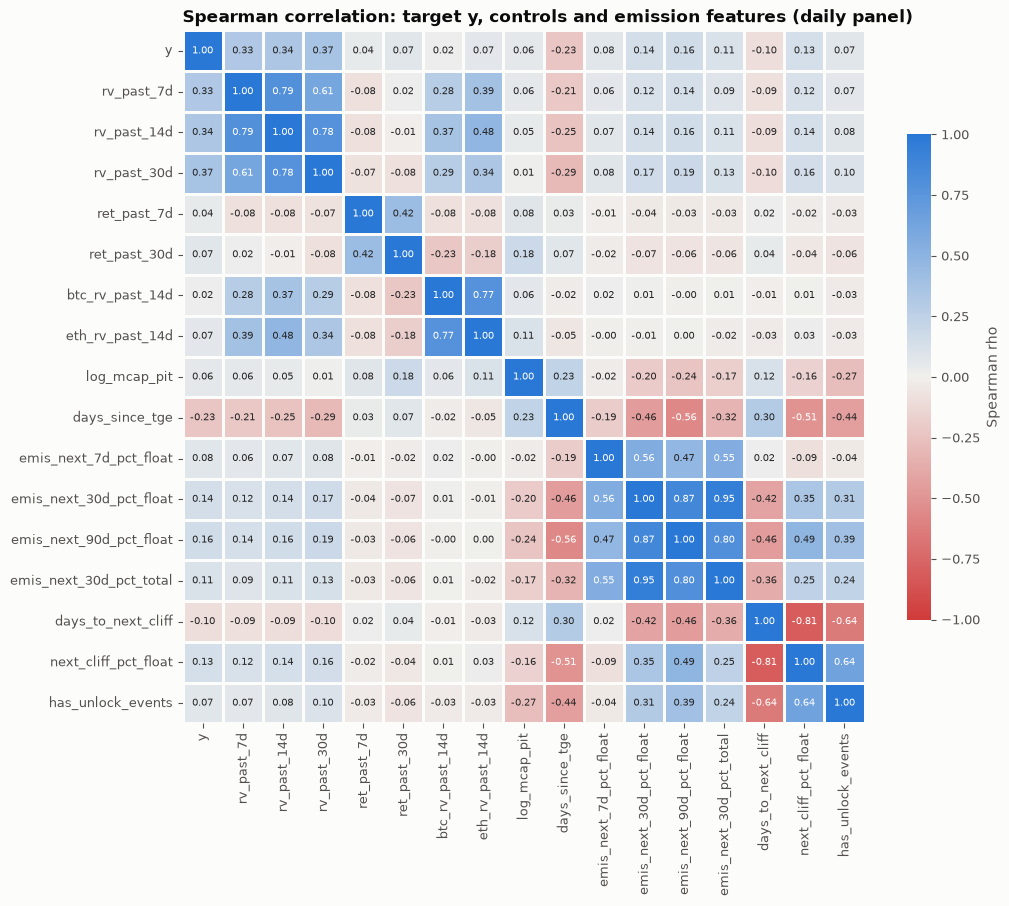

[figure] figures\eda_correlation_heatmap.png


WindowsPath('D:/ML-project/figures/eda_correlation_heatmap.png')

In [6]:
# ---- 3. correlation heatmap ----------------------------------------------
top_emis = ["emis_next_7d_pct_float", "emis_next_30d_pct_float",
            "emis_next_90d_pct_float", "emis_next_30d_pct_total",
            "days_to_next_cliff", "next_cliff_pct_float", "has_unlock_events"]
cols = ["y"] + CONTROLS + top_emis
corr = daily[cols].corr(method="spearman")
cmap = LinearSegmentedColormap.from_list("div", ["#d03b3b", "#f0efec", "#2a78d6"])
fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(corr, cmap=cmap, vmin=-1, vmax=1, center=0, annot=True, fmt=".2f",
            annot_kws={"size": 7}, linewidths=1, linecolor=SURFACE,
            cbar_kws={"label": "Spearman rho", "shrink": 0.7}, ax=ax)
ax.grid(False)
ax.set_title("Spearman correlation: target y, controls and emission features "
             "(daily panel)")
savefig(fig, "eda_correlation_heatmap.png")


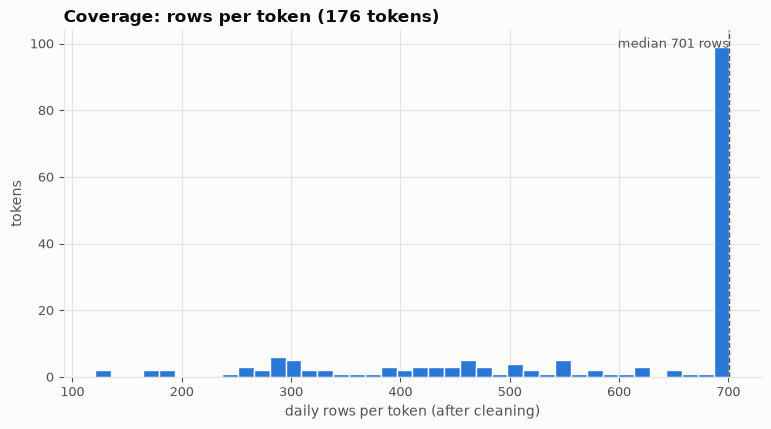

[figure] figures\eda_rows_per_token.png


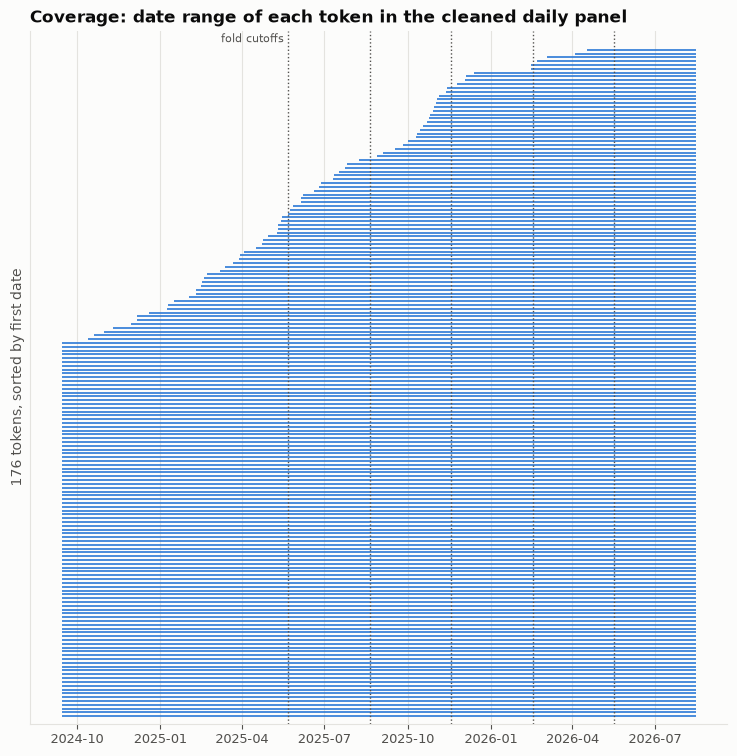

[figure] figures\eda_token_date_ranges.png


WindowsPath('D:/ML-project/figures/eda_token_date_ranges.png')

In [7]:
# ---- 4. per-token coverage ------------------------------------------------
cov = daily.groupby("token_id")["date"].agg(["count", "min", "max"]).sort_values(
    ["min", "max"], ascending=[True, False])
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.hist(cov["count"], bins=40, color=PALETTE[0], edgecolor=SURFACE)
ax.axvline(cov["count"].median(), color=INK_2, linestyle="--", linewidth=1)
ax.text(cov["count"].median(), ax.get_ylim()[1] * 0.95,
        f" median {cov['count'].median():.0f} rows", color=INK_2, fontsize=9,
        ha="right")
ax.set_xlabel("daily rows per token (after cleaning)")
ax.set_ylabel("tokens")
ax.set_title(f"Coverage: rows per token ({len(cov)} tokens)")
savefig(fig, "eda_rows_per_token.png")

fig, ax = plt.subplots(figsize=(9, 9))
ypos = np.arange(len(cov))
ax.hlines(ypos, cov["min"], cov["max"], color=PALETTE[0], linewidth=1.2)
folds = folds_daily
for c in folds.cutoffs:
    ax.axvline(c, color=INK_2, linestyle=":", linewidth=1)
ax.text(folds.cutoffs[0], len(cov) + 1, "fold cutoffs ", color=INK_2,
        fontsize=8, ha="right")
ax.set_yticks([])
ax.set_ylabel(f"{len(cov)} tokens, sorted by first date")
ax.set_ylim(-2, len(cov) + 4)
ax.grid(axis="y", visible=False)
ax.set_title("Coverage: date range of each token in the cleaned daily panel")
savefig(fig, "eda_token_date_ranges.png")


### 3.5 Summary table

Row counts, date range, the pooled and per-token Spearman correlation between the 30-day unlock-pressure feature and the target, and null rates after cleaning (all zero).


In [8]:
# ---- 5. summary table -----------------------------------------------------
raw = pd.read_csv(DATA_PATH, usecols=["days_to_next_cliff", "unlockPrecision"])
pooled = spearmanr(daily["emis_next_30d_pct_float"], daily["y"]).statistic
per_tok = daily.groupby("token_id").apply(
    lambda d: spearmanr(d["emis_next_30d_pct_float"], d["y"]).statistic
    if d["emis_next_30d_pct_float"].nunique() > 1 else np.nan,
    include_groups=False)
rows = [
    ("rows_daily", len(daily)), ("rows_weekly", len(weekly)),
    ("tokens", daily["token_id"].nunique()),
    ("date_min", daily["date"].min().date()), ("date_max", daily["date"].max().date()),
    ("rows_per_token_median", cov["count"].median()),
    ("rows_per_token_min", cov["count"].min()),
    ("spearman_emis30_y_pooled", round(pooled, 4)),
    ("spearman_emis30_y_per_token_median", round(per_tok.median(), 4)),
    ("spearman_emis30_y_per_token_n", int(per_tok.notna().sum())),
    ("spearman_emis30_y_per_token_share_positive",
     round((per_tok.dropna() > 0).mean(), 4)),
    ("raw_null_rate_days_to_next_cliff (filled 365)",
     round(raw["days_to_next_cliff"].isna().mean(), 4)),
    ("raw_null_rate_unlockPrecision (-> unknown)",
     round(raw["unlockPrecision"].isna().mean(), 4)),
]
rows += [(f"null_rate_after_cleaning:{c}", round(daily[c].isna().mean(), 4))
         for c in FULL]
summary = pd.DataFrame(rows, columns=["metric", "value"])
if not SMOKE:
    RESULTS_DIR.mkdir(exist_ok=True)
    summary.to_csv(RESULTS_DIR / "eda_summary.csv", index=False)
print(summary.head(13).to_string(index=False))
print(f"max null rate after cleaning: {daily[FULL].isna().mean().max():.4f}")


                                       metric      value
                                   rows_daily     101393
                                  rows_weekly      14623
                                       tokens        176
                                     date_min 2024-09-14
                                     date_max 2026-08-15
                        rows_per_token_median      701.0
                           rows_per_token_min        121
                     spearman_emis30_y_pooled     0.1419
           spearman_emis30_y_per_token_median     0.2195
                spearman_emis30_y_per_token_n        174
   spearman_emis30_y_per_token_share_positive     0.7356
raw_null_rate_days_to_next_cliff (filled 365)     0.5111
   raw_null_rate_unlockPrecision (-> unknown)     0.3317
max null rate after cleaning: 0.0000


## 4. Baselines

Two forecasts that use no model: **persistence** (`log rv_past_14d`, the benchmark inside `r2_oos`) and the **pooled train mean**. Note that the train mean already beats persistence, so every model is compared against both.


In [9]:
baseline_res = pd.concat([baselines(df, folds, freq=freq, save=not SMOKE)
                          for freq, (df, folds) in data.items()], ignore_index=True)
display(baseline_res.groupby(["freq", "model"])[["rmse", "mae", "r2_oos", "spearman"]].mean().round(4))

rmse     mae  r2_oos  spearman
freq   model                                        
daily  persistence  0.5269  0.4101  0.0000    0.2462
       train_mean   0.4713  0.3811  0.1698       NaN
weekly persistence  0.5274  0.4067  0.0000    0.2604
       train_mean   0.4733  0.3818  0.1656       NaN

## 5. K-nearest-neighbours regression

A `QuantileTransformer` (fit on training rows only) maps every feature to a normal scale so that distances are comparable, followed by `KNeighborsRegressor`. The grid is `k in {5, 10, 25, 50, 100, 250}` x `{uniform, distance}` weights. Three feature sets on both panels.


In [10]:
KNN_NAME = "knn"
KNN_FEATURE_SETS = ["CONTROLS", "CONTROLS+EMIS5", "FULL"]
KNN_GRID = {"n_neighbors": [5, 10, 25, 50, 100, 250],
              "weights": ["uniform", "distance"]}
N_SHOWN = 15  # neighbours drawn in the illustration (the table has all k)


def knn_factory(**params) -> Pipeline:
    return Pipeline([
        ("qt", QuantileTransformer(output_distribution="normal",
                                   n_quantiles=1000,
                                   random_state=RANDOM_STATE)),
        ("knn", KNeighborsRegressor(algorithm="brute", n_jobs=-1, **params)),
    ])


In [11]:
knn_results = []
for freq, (df, folds) in data.items():
    for fs in KNN_FEATURE_SETS:
        grid = {"n_neighbors": [25, 100], "weights": ["uniform"]} if SMOKE else KNN_GRID
        done = finished_run(KNN_NAME, folds, fs, freq)
        knn_results.append(done if done is not None else
                           run_model(KNN_NAME, knn_factory, df, folds, fs, grid, freq, save=not SMOKE))
knn_res = pd.concat(knn_results, ignore_index=True)

knn_summary = (knn_res.groupby(["freq", "feature_set"], sort=False)
                      [["rmse", "mae", "r2_oos", "spearman"]].mean())
print("KNN mean over folds:")
display(knn_summary.round(4))
for freq in data:
    a = knn_summary.loc[(freq, "CONTROLS"), "rmse"]
    c = knn_summary.loc[(freq, "FULL"), "rmse"]
    verdict = "DEGRADES" if c > a else "improves"
    print(f"[{freq}] RMSE CONTROLS {a:.4f} -> FULL {c:.4f}: adding emission+static "
          f"features {verdict} KNN (a result, not a bug)")


[knn|CONTROLS_daily] found in results/knn.csv, reusing (mean rmse 0.4526, r2_oos +0.2337); set NB_FRESH=1 to recompute
[knn|CONTROLS+EMIS5_daily] found in results/knn.csv, reusing (mean rmse 0.4507, r2_oos +0.2401); set NB_FRESH=1 to recompute
[knn|FULL_daily] found in results/knn.csv, reusing (mean rmse 0.4538, r2_oos +0.2350); set NB_FRESH=1 to recompute
[knn|CONTROLS_weekly] found in results/knn.csv, reusing (mean rmse 0.4534, r2_oos +0.2322); set NB_FRESH=1 to recompute
[knn|CONTROLS+EMIS5_weekly] found in results/knn.csv, reusing (mean rmse 0.4524, r2_oos +0.2386); set NB_FRESH=1 to recompute
[knn|FULL_weekly] found in results/knn.csv, reusing (mean rmse 0.4576, r2_oos +0.2245); set NB_FRESH=1 to recompute
KNN mean over folds:


rmse     mae  r2_oos  spearman
freq   feature_set                                     
daily  CONTROLS        0.4526  0.3598  0.2337    0.2615
       CONTROLS+EMIS5  0.4507  0.3594  0.2401    0.2663
       FULL            0.4538  0.3650  0.2350    0.2740
weekly CONTROLS        0.4534  0.3592  0.2322    0.2440
       CONTROLS+EMIS5  0.4524  0.3597  0.2386    0.2352
       FULL            0.4576  0.3672  0.2245    0.2606

[daily] RMSE CONTROLS 0.4526 -> FULL 0.4538: adding emission+static features DEGRADES KNN (a result, not a bug)
[weekly] RMSE CONTROLS 0.4534 -> FULL 0.4576: adding emission+static features DEGRADES KNN (a result, not a bug)


### 5.1 Validation curve and a neighbour illustration

The validation curve shows RMSE against k for each feature set (mean over folds, better of the two weightings). The illustration picks the most unlock-heavy test row of the last fold and shows its nearest training rows: who the model thinks the comparable token-days are, and what happened to them.


In [12]:
def plot_val_curve():
    """Validation RMSE vs k (daily), one line per feature set. Each point is
    the mean over folds, using the better of the two weightings at that k."""
    fig, ax = plt.subplots(figsize=(9, 5))
    for i, fs in enumerate(KNN_FEATURE_SETS):
        val = pd.read_csv(RESULTS_DIR / f"val_{KNN_NAME}_{run_tag(fs, 'daily')}.csv")
        curve = (val.groupby(["n_neighbors", "weights"])["val_rmse"].mean()
                    .unstack("weights").min(axis=1))
        ax.plot(curve.index, curve.values, marker="o", color=PALETTE[i],
                label=f"{fs} ({len(FEATURE_SETS[fs])} features), "
                      f"best {curve.min():.4f} at k={curve.idxmin()}")
    ax.set_xscale("log")
    ax.set_xticks(KNN_GRID["n_neighbors"])
    ax.set_xticklabels(KNN_GRID["n_neighbors"])
    ax.minorticks_off()
    ax.set_xlabel("k (n_neighbors, log scale)")
    ax.set_ylabel("validation RMSE, log-vol (mean of 5 folds)")
    ax.set_title("KNN: validation RMSE vs k by feature set (daily panel)")
    ax.legend(title="feature set")
    savefig(fig, "knn_val_rmse_vs_k.png")


def neighbour_illustration(df, folds, res, fs="CONTROLS+EMIS5"):
    """Who are the neighbours of the most unlock-heavy test row?"""
    features = FEATURE_SETS[fs]
    tr, _, te = folds[-1]
    row = res[(res.feature_set == fs) & (res.freq == "daily")
              & (res.fold == len(folds))].iloc[0]
    params = json.loads(row["best_params"])
    pipe = knn_factory(**params).fit(df.iloc[tr][features].to_numpy(float),
                                     df.iloc[tr]["y"].to_numpy())

    q_pos = te[np.argmax(df["emis_next_30d_pct_float"].to_numpy()[te])]
    q = df.iloc[[q_pos]]
    xq = pipe.named_steps["qt"].transform(q[features].to_numpy(float))
    dist, idx = pipe.named_steps["knn"].kneighbors(xq)
    nb = df.iloc[tr[idx[0]]]

    def table(d, role, distance):
        return pd.DataFrame({
            "role": role, "token_id": d["token_id"].values,
            "date": d["date"].dt.date.values, "distance": distance,
            "emis_next_30d_pct_float": np.expm1(d["emis_next_30d_pct_float"].values),
            "rv_past_14d": d["rv_past_14d"].values,
            "rv_fwd_14d": np.exp(d["y"].values)})

    out = pd.concat([table(q, "query", 0.0), table(nb, "neighbour", dist[0])],
                    ignore_index=True)
    pred = float(np.exp(pipe.predict(q[features].to_numpy(float))[0]))
    out["knn_pred_rv_fwd_14d"] = pred
    out.to_csv(RESULTS_DIR / "knn_neighbours.csv", index=False)
    print(f"\nNeighbour illustration ({fs}, fold {len(folds)}, {params}); "
          f"KNN prediction {pred:.3f} vs realized {out.loc[0, 'rv_fwd_14d']:.3f}")
    print(out.head(N_SHOWN + 1).round(4).to_string(index=False))

    shown = out.head(N_SHOWN + 1)
    labels = ["QUERY\n" + shown.loc[0, "token_id"]] + [
        f"{t}\n{d:%y-%m-%d}" for t, d in zip(shown["token_id"][1:], shown["date"][1:])]
    colors = [PALETTE[1]] + [PALETTE[0]] * (len(shown) - 1)
    panels = [("emis_next_30d_pct_float", "share of float unlocking in next 30d"),
              ("rv_past_14d", "rv_past_14d (known at D)"),
              ("rv_fwd_14d", "realized rv_fwd_14d (target, level)")]
    fig, axes = plt.subplots(3, 1, figsize=(12, 9.5), sharex=True)
    for ax, (col, title) in zip(axes, panels):
        ax.bar(range(len(shown)), shown[col], color=colors, width=0.7)
        ax.set_title(title, fontsize=10)
        ax.grid(axis="x", visible=False)
        ax.text(0, shown[col].iloc[0], f"{shown[col].iloc[0]:.2f}", ha="center",
                va="bottom", fontsize=8, color=INK_2)
    axes[2].axhline(pred, color=INK_2, linestyle="--", linewidth=1.2)
    axes[2].set_title(f"realized rv_fwd_14d (target, level); dashed = KNN "
                      f"prediction {pred:.2f} from all k={params['n_neighbors']} "
                      f"neighbours ({params['weights']} weights)", fontsize=10)
    axes[2].set_xticks(range(len(shown)))
    axes[2].set_xticklabels(labels, fontsize=7)
    qd = shown.loc[0, "date"]
    fig.suptitle(
        f"KNN neighbours of the most unlock-heavy test row: "
        f"{shown.loc[0, 'token_id']} on {qd} (orange) vs its {len(shown) - 1} "
        f"nearest training rows (blue, nearest first)\nfeature set {fs}, "
        f"last fold", x=0.01, ha="left", fontweight="bold", fontsize=11)
    fig.tight_layout()
    savefig(fig, "knn_neighbour_illustration.png")


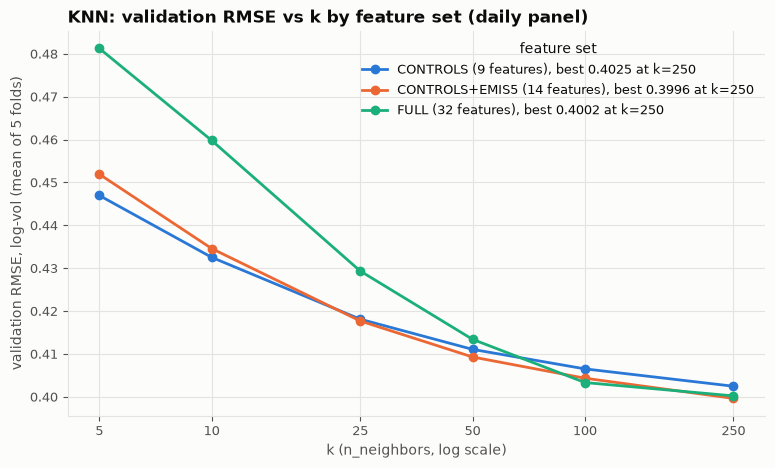

[figure] figures\knn_val_rmse_vs_k.png



Neighbour illustration (CONTROLS+EMIS5, fold 5, {'n_neighbors': 250, 'weights': 'distance'}); KNN prediction 0.779 vs realized 0.554
     role       token_id       date  distance  emis_next_30d_pct_float  rv_past_14d  rv_fwd_14d  knn_pred_rv_fwd_14d
    query       succinct 2026-07-06    0.0000                   1.0417       0.4170      0.5535               0.7789
neighbour    sign-global 2026-01-13    1.7999                   0.1768       0.3899      0.6382               0.7789
neighbour      treehouse 2026-01-17    1.9237                   0.3941       0.3935      1.6557               0.7789
neighbour    sign-global 2026-01-14    1.9242                   0.1768       0.4293      0.6602               0.7789
neighbour      treehouse 2026-01-16    1.9891                   0.3941       0.3960      1.4432               0.7789
neighbour    sign-global 2026-01-11    2.0616                   0.1768       0.3466      0.6571               0.7789
neighbour    sign-global 2026-01-12    2.0832  

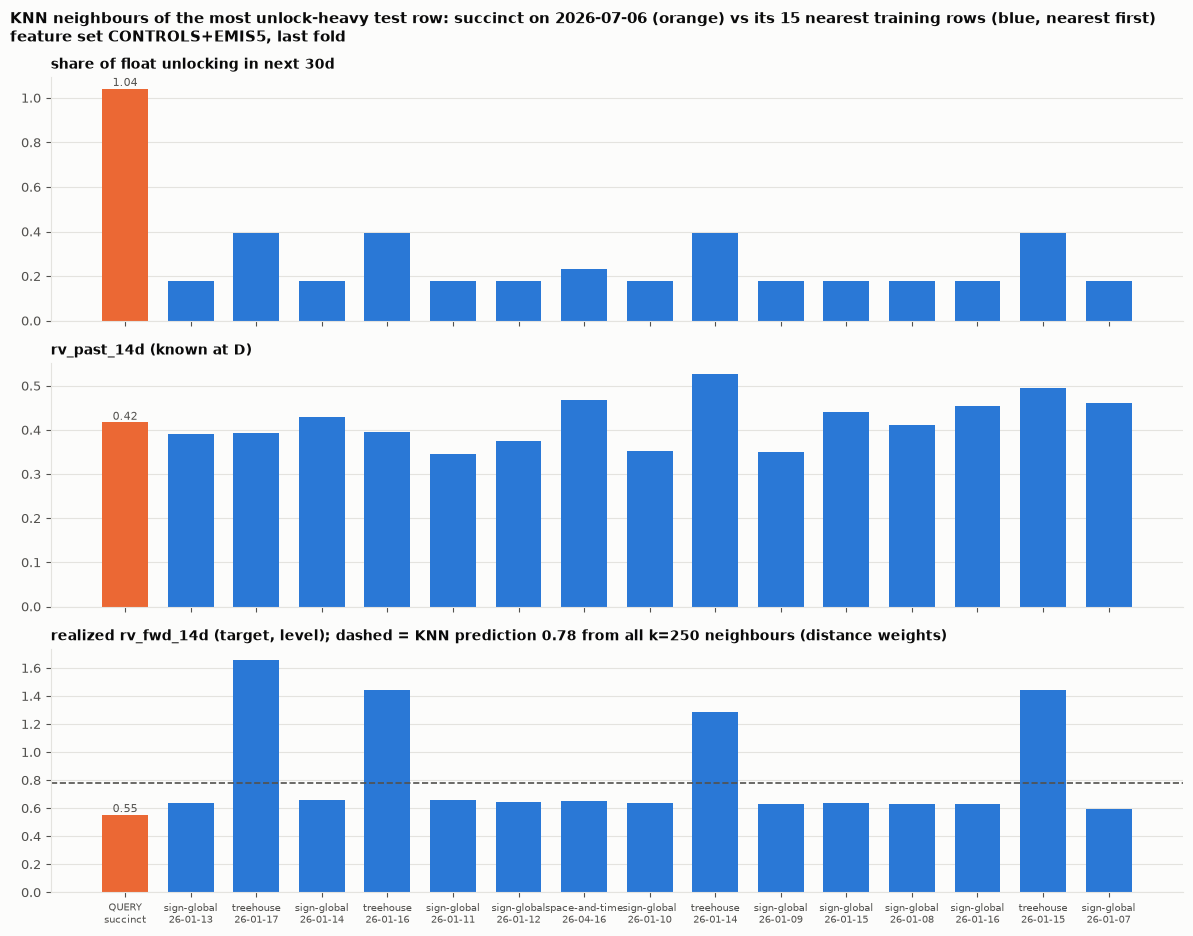

[figure] figures\knn_neighbour_illustration.png


In [13]:
if not SMOKE:
    plot_val_curve()          # reads results/val_knn_*.csv written by run_model
neighbour_illustration(*data["daily"], knn_res)


## 6. Random Forest

400 trees; grid over `max_depth`, `min_samples_leaf`, `max_features` (36 configs). Following the project rule of subsampling the grid rather than dropping the protocol, the daily runs evaluate a fixed, seeded random subset of the grid (12 configs for the main runs, 6 for robustness runs); the weekly runs use the full grid. The fold protocol is unchanged.

### 6.1 Main runs: CONTROLS vs FULL, weekly and daily


In [14]:
RF_NAME = "rf"
N_TREES = 30 if SMOKE else 400
RF_GRID = {"max_depth": [None, 8, 12, 16],
              "min_samples_leaf": [20, 50, 100],
              "max_features": ["sqrt", 0.33, 0.5]}
# configs evaluated per fold (None = full grid of 36)
BUDGET = {"daily_main": 12, "daily_robust": 6, "weekly": None}
if SMOKE:
    BUDGET = {k: 2 for k in BUDGET}

GROUP_COLOR = {"controls": PALETTE[0], "emission": PALETTE[1],
               "static": PALETTE[2]}


def group_of(feature: str) -> str:
    return ("controls" if feature in CONTROLS else
            "emission" if feature in EMISSION else "static")


def rf_factory(**params) -> Pipeline:
    # trees need no scaling; the Pipeline wrapper keeps the harness contract
    return Pipeline([("rf", RandomForestRegressor(
        n_estimators=N_TREES, n_jobs=-1, random_state=RANDOM_STATE, **params))])


def run(df, folds, fs, freq, budget, **kw):
    done = finished_run(RF_NAME, folds, fs, freq, **kw)
    if done is not None:
        return done
    return run_model(RF_NAME, rf_factory, df, folds, fs, RF_GRID, freq,
                       max_configs=BUDGET[budget], save=not SMOKE, **kw)

def main_runs():
    out = []
    for freq in ("weekly", "daily"):
        df, folds = data[freq]
        for fs in ("CONTROLS", "FULL"):
            out.append(run(df, folds, fs, freq,
                           "weekly" if freq == "weekly" else "daily_main"))
    return pd.concat(out)


def robustness_runs(df, folds):
    out = []
    for target in ("y_14d_parkinson", "y_7d", "y_30d"):
        baselines(df, folds, freq="daily", target=target, save=not SMOKE)
        out.append(run(df, folds, "FULL", "daily", "daily_robust", target=target))

    sub = df[df["listedMethod_INTERNAL"] == 1].reset_index(drop=True)
    print(f"[subsample INTERNAL] {len(sub):,d} rows, "
          f"{sub['token_id'].nunique()} tokens")
    sub_folds = make_folds(sub)
    baselines(sub, sub_folds, freq="daily", subsample="INTERNAL", save=not SMOKE)
    # controls-only on the same subsample, so the FULL number has a reference
    for fs in ("CONTROLS", "FULL"):
        out.append(run(sub, sub_folds, fs, "daily", "daily_robust",
                       subsample="INTERNAL"))
    return pd.concat(out)


In [15]:
rf_main_res = main_runs()


[rf|CONTROLS_weekly] found in results/rf.csv, reusing (mean rmse 0.4510, r2_oos +0.2343); set NB_FRESH=1 to recompute
[rf|FULL_weekly] found in results/rf.csv, reusing (mean rmse 0.4500, r2_oos +0.2410); set NB_FRESH=1 to recompute
[rf|CONTROLS_daily] found in results/rf.csv, reusing (mean rmse 0.4451, r2_oos +0.2617); set NB_FRESH=1 to recompute
[rf|FULL_daily] found in results/rf.csv, reusing (mean rmse 0.4431, r2_oos +0.2681); set NB_FRESH=1 to recompute


### 6.2 Robustness

The same comparison on three alternative targets (Parkinson 14-day, 7-day and 30-day forward volatility) and on the subsample of tokens that Tokenomist curates by hand (`listedMethod == INTERNAL`), with a controls-only run on the same subsample as reference.


In [16]:
rf_robust_res = robustness_runs(*data["daily"])
rf_res = pd.concat([rf_main_res, rf_robust_res], ignore_index=True)
print("RF mean over folds:")
display(rf_res.groupby(["freq", "target", "subsample", "feature_set"], sort=False)
              [["rmse", "mae", "r2_oos", "spearman"]].mean().round(4))


[rf|FULL_daily_log_rv_fwd_14d_parkinson] found in results/rf.csv, reusing (mean rmse 0.4342, r2_oos +0.3539); set NB_FRESH=1 to recompute
[rf|FULL_daily_log_rv_fwd_7d] found in results/rf.csv, reusing (mean rmse 0.4983, r2_oos +0.2347); set NB_FRESH=1 to recompute


[rf|FULL_daily_log_rv_fwd_30d] found in results/rf.csv, reusing (mean rmse 0.3893, r2_oos +0.3885); set NB_FRESH=1 to recompute
[subsample INTERNAL] 87,684 rows, 150 tokens
[make_folds] fold 1 cutoff 2025-05-22 | train 21,268 2024-09-14..2025-04-22 | val  9,190 2025-01-23..2025-04-22 | test 11,082 2025-05-23..2025-08-20
[make_folds] fold 2 cutoff 2025-08-20 | train 31,887 2024-09-14..2025-07-21 | val 10,619 2025-04-23..2025-07-21 | test 12,063 2025-08-21..2025-11-18
[make_folds] fold 3 cutoff 2025-11-18 | train 43,561 2024-09-14..2025-10-19 | val 11,674 2025-07-22..2025-10-19 | test 13,039 2025-11-19..2026-02-16
[make_folds] fold 4 cutoff 2026-02-16 | train 56,455 2024-09-14..2026-01-17 | val 12,894 2025-10-20..2026-01-17 | test 13,376 2026-02-17..2026-05-17
[make_folds] fold 5 cutoff 2026-05-17 | train 69,684 2024-09-14..2026-04-17 | val 13,229 2026-01-18..2026-04-17 | test 13,500 2026-05-18..2026-08-15


[rf|CONTROLS_daily_INTERNAL] found in results/rf.csv, reusing (mean rmse 0.4416, r2_oos +0.2597); set NB_FRESH=1 to recompute
[rf|FULL_daily_INTERNAL] found in results/rf.csv, reusing (mean rmse 0.4371, r2_oos +0.2763); set NB_FRESH=1 to recompute
RF mean over folds:


rmse     mae  r2_oos  spearman
freq   target                   subsample feature_set                                  
weekly log_rv_fwd_14d           all       CONTROLS     0.4510  0.3608  0.2343    0.3013
                                          FULL         0.4500  0.3601  0.2410    0.3095
daily  log_rv_fwd_14d           all       CONTROLS     0.4451  0.3553  0.2617    0.3054
                                          FULL         0.4431  0.3547  0.2681    0.3259
       log_rv_fwd_14d_parkinson all       FULL         0.4342  0.3360  0.3539    0.4044
       log_rv_fwd_7d            all       FULL         0.4983  0.3885  0.2347    0.3300
       log_rv_fwd_30d           all       FULL         0.3893  0.3195  0.3885    0.3398
       log_rv_fwd_14d           INTERNAL  CONTROLS     0.4416  0.3530  0.2597    0.3083
                                          FULL         0.4371  0.3505  0.2763    0.3342

### 6.3 Interpretation (last fold, FULL config)

Permutation importance on the test set (increase in RMSE when a feature is shuffled, 10 repeats) next to impurity importance; the same for a variant that removes the aggregate 30-day feature so the six recipient-split columns have to carry the signal; and partial dependence of the prediction on 30-day unlock pressure, alone and against the BTC volatility regime.


In [17]:
def importances(est, X_te, y_te, features, variant):
    pi = permutation_importance(est, X_te, y_te, n_repeats=10,
                                random_state=RANDOM_STATE,
                                scoring="neg_root_mean_squared_error")
    return pd.DataFrame({
        "model_variant": variant, "feature": features,
        "group": [group_of(f) for f in features],
        "perm_importance_mean": pi.importances_mean,
        "perm_importance_std": pi.importances_std,
        "impurity_importance": est.named_steps["rf"].feature_importances_,
    }).sort_values("perm_importance_mean", ascending=False)


def interpret(df, folds, params):
    tr, _, te = folds[-1]
    y = df["y"].to_numpy()
    print(f"[interpret] last fold, FULL config {params}")

    fitted, imps = {}, []
    for variant in ("FULL", "FULL_NO_AGG30"):
        feats = FEATURE_SETS[variant]
        t0 = time.perf_counter()
        X = df[feats].to_numpy(float)
        est = rf_factory(**params).fit(X[tr], y[tr])
        rmse = float(np.sqrt(np.mean((y[te] - est.predict(X[te])) ** 2)))
        imps.append(importances(est, X[te], y[te], feats, variant))
        fitted[variant] = (est, X)
        print(f"[interpret] {variant}: test rmse {rmse:.4f} "
              f"({time.perf_counter() - t0:.1f}s incl. permutation importance)")
    imp = pd.concat(imps, ignore_index=True)
    imp.to_csv(RESULTS_DIR / "rf_permutation_importance.csv", index=False)
    full = imp[imp.model_variant == "FULL"]
    print(full.head(15).round(5).to_string(index=False))

    plot_importance(full)
    plot_recipient_split(imp)
    plot_pdp(*fitted["FULL"], te)


def plot_importance(full):
    top = full.head(15).iloc[::-1]
    colors = [GROUP_COLOR[g] for g in top["group"]]
    fig, axes = plt.subplots(1, 2, figsize=(13, 6.5), sharey=True)
    axes[0].barh(top["feature"], top["perm_importance_mean"],
                 xerr=top["perm_importance_std"], color=colors, height=0.7,
                 error_kw={"ecolor": INK_2, "elinewidth": 1})
    axes[0].axvline(0, color=INK_2, linewidth=0.8)
    axes[0].set_title("Permutation importance on the TEST set\n"
                      "(increase in RMSE when shuffled, 10 repeats)", fontsize=10)
    axes[0].set_xlabel("increase in test RMSE (log-vol)")
    axes[1].barh(top["feature"], top["impurity_importance"], color=colors,
                 height=0.7)
    axes[1].set_title("Impurity importance (training set)\n"
                      "same features, same order", fontsize=10)
    axes[1].set_xlabel("share of impurity reduction")
    for ax in axes:
        ax.grid(axis="y", visible=False)
    axes[1].legend(handles=[Patch(color=c, label=g) for g, c in GROUP_COLOR.items()],
                   title="feature group", loc="lower right")
    fig.suptitle("Random Forest (FULL, last fold): top 15 features by "
                 "permutation importance", x=0.01, ha="left", fontweight="bold")
    fig.tight_layout()
    savefig(fig, "rf_permutation_importance_top15.png")


def plot_recipient_split(imp):
    piv = (imp[imp.feature.isin(EMISSION_BUCKETS + ["emis_next_30d_pct_float"])]
           .pivot(index="feature", columns="model_variant",
                  values=["perm_importance_mean", "perm_importance_std"]))
    order = ["emis_next_30d_pct_float"] + EMISSION_BUCKETS
    piv = piv.reindex(order)
    labels = ["aggregate\n(all recipients)"] + BUCKETS
    x = np.arange(len(order))
    fig, ax = plt.subplots(figsize=(11, 5))
    for i, (variant, label) in enumerate(
            [("FULL", "FULL (aggregate included)"),
             ("FULL_NO_AGG30", "recipient split (aggregate removed)")]):
        ax.bar(x + (i - 0.5) * 0.38, piv[("perm_importance_mean", variant)],
               yerr=piv[("perm_importance_std", variant)], width=0.36,
               color=PALETTE[i], label=label,
               error_kw={"ecolor": INK_2, "elinewidth": 1})
    ax.axhline(0, color=INK_2, linewidth=0.8)
    ax.set_xticks(x)
    ax.set_xticklabels(labels)
    ax.grid(axis="x", visible=False)
    ax.set_ylabel("permutation importance\n(increase in test RMSE, log-vol)")
    ax.set_xlabel("emis_next_30d_<recipient>_pct_float")
    ax.set_title("Permutation importance of 30-day emission by recipient "
                 "(RF, last fold)", fontsize=11)
    ax.legend()
    savefig(fig, "rf_recipient_split_importance.png")
    print(piv["perm_importance_mean"].round(5).to_string())


def plot_pdp(est, X, te):
    feats = FULL
    i_e, i_b = feats.index("emis_next_30d_pct_float"), feats.index("btc_rv_past_14d")
    rng = np.random.default_rng(RANDOM_STATE)
    Xs = X[np.sort(rng.choice(te, size=min(3000, len(te)), replace=False))]

    pd1 = partial_dependence(est, Xs, [i_e], percentiles=(0, 0.99),
                             grid_resolution=40, kind="average")
    gx = np.expm1(pd1["grid_values"][0])
    fig, ax = plt.subplots(figsize=(9, 5))
    ax.plot(gx * 100, pd1["average"][0], color=PALETTE[0])
    deciles = np.expm1(np.quantile(X[te, i_e], np.linspace(0.1, 0.9, 9))) * 100
    ax.plot(deciles, np.full(9, ax.get_ylim()[0]), "|", color=INK_2,
            markersize=12, clip_on=False)
    ax.set_xlabel("share of float unlocking in the next 30 days, % "
                  "(ticks at the bottom = test-set deciles)")
    ax.set_ylabel("partial dependence: predicted log(rv_fwd_14d)")
    span = pd1["average"][0].max() - pd1["average"][0].min()
    ax.set_title("RF partial dependence on 30-day unlock pressure (FULL, last "
                 f"fold)\ntotal range of the curve: {span:.3f} log-vol",
                 fontsize=11)
    savefig(fig, "rf_pdp_emis30.png")

    pd2 = partial_dependence(est, Xs, [(i_e, i_b)], percentiles=(0, 0.99),
                             grid_resolution=20, kind="average")
    ge, gb = pd2["grid_values"]
    cmap = LinearSegmentedColormap.from_list(
        "seq", ["#cde2fb", "#6da7ec", "#2a78d6", "#0d366b"])
    fig, ax = plt.subplots(figsize=(9, 6))
    cs = ax.contourf(np.expm1(ge) * 100, gb, pd2["average"][0].T, levels=12,
                     cmap=cmap)
    ax.contour(np.expm1(ge) * 100, gb, pd2["average"][0].T, levels=12,
               colors=SURFACE, linewidths=0.5, negative_linestyles="solid")
    fig.colorbar(cs, ax=ax, label="predicted log(rv_fwd_14d)")
    ax.grid(False)
    ax.set_xlabel("share of float unlocking in the next 30 days, %")
    ax.set_ylabel("btc_rv_past_14d (market vol regime)")
    ax.set_title("RF 2-D partial dependence: unlock pressure x BTC vol regime",
                 fontsize=11)
    savefig(fig, "rf_pdp_emis30_x_btc.png")


[interpret] last fold, FULL config {'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 100}


[interpret] FULL: test rmse 0.5088 (117.9s incl. permutation importance)


[interpret] FULL_NO_AGG30: test rmse 0.5083 (110.4s incl. permutation importance)
model_variant                 feature    group  perm_importance_mean  perm_importance_std  impurity_importance
         FULL             rv_past_30d controls               0.01123              0.00040              0.12480
         FULL             rv_past_14d controls               0.01025              0.00024              0.10693
         FULL              rv_past_7d controls               0.00477              0.00024              0.07963
         FULL            ret_past_30d controls               0.00359              0.00018              0.07082
         FULL          days_since_tge controls               0.00335              0.00014              0.08303
         FULL emis_next_90d_pct_float emission               0.00217              0.00011              0.03409
         FULL alloc_share_founderTeam   static               0.00189              0.00005              0.02461
         FULL emis_next_30d_pc

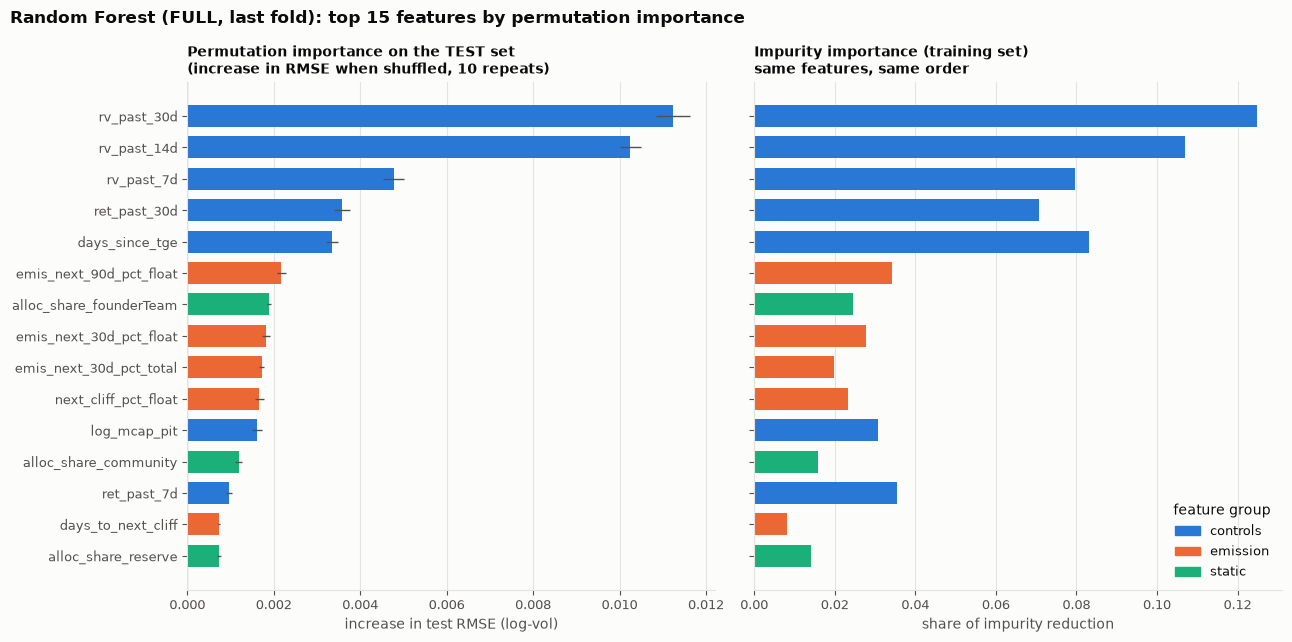

[figure] figures\rf_permutation_importance_top15.png


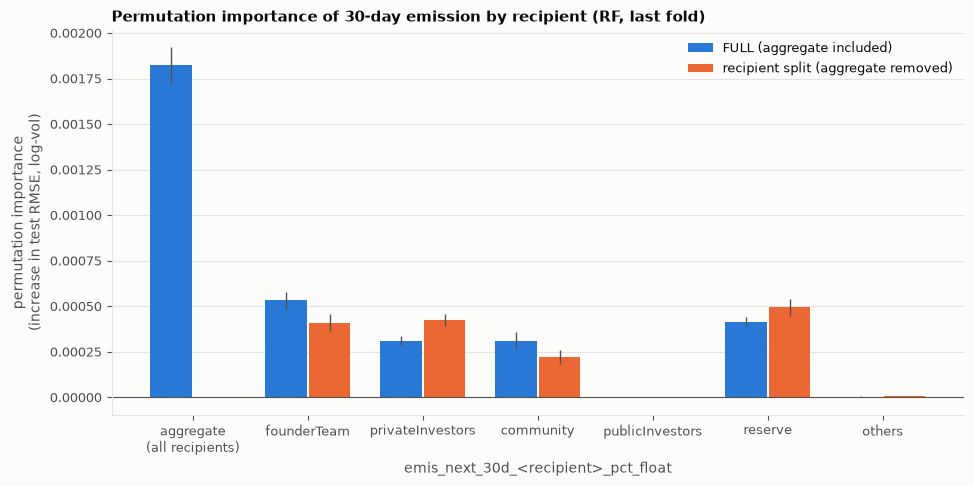

[figure] figures\rf_recipient_split_importance.png
model_variant                                FULL  FULL_NO_AGG30
feature                                                         
emis_next_30d_pct_float                   0.00182            NaN
emis_next_30d_founderTeam_pct_float       0.00053        0.00041
emis_next_30d_privateInvestors_pct_float  0.00031        0.00042
emis_next_30d_community_pct_float         0.00031        0.00022
emis_next_30d_publicInvestors_pct_float   0.00000        0.00000
emis_next_30d_reserve_pct_float           0.00042        0.00049
emis_next_30d_others_pct_float            0.00000        0.00001


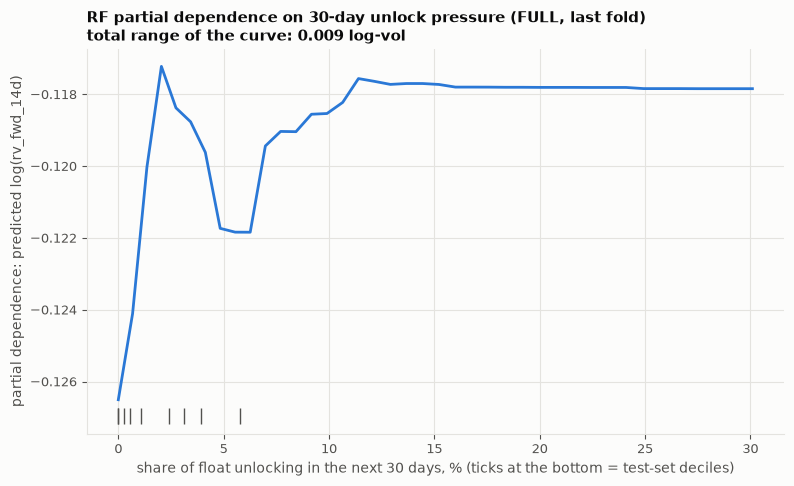

[figure] figures\rf_pdp_emis30.png


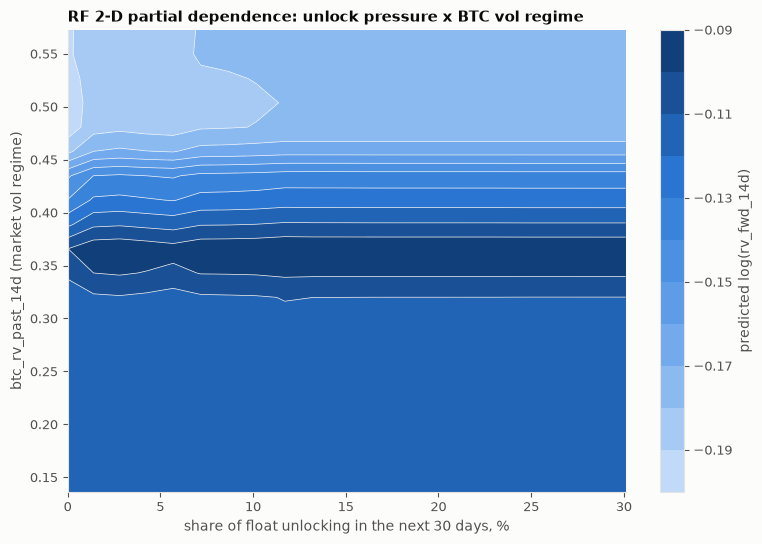

[figure] figures\rf_pdp_emis30_x_btc.png


In [18]:
df_d, folds_d = data["daily"]
best = rf_res[(rf_res.feature_set == "FULL") & (rf_res.freq == "daily")
              & (rf_res.target == TARGETS["y"]) & (rf_res.subsample == "all")
              & (rf_res.fold == len(folds_d))]
interpret(df_d, folds_d, json.loads(best.iloc[0]["best_params"]))


## 7. Ridge and Elastic Net regression

Linear benchmarks on the same rows, features, folds and tuning protocol as KNN and RF. Inside each `Pipeline` the volatility controls (`rv_past_*`, BTC/ETH vol) are logged and `days_since_tge` is log1p'd (a fixed transform, nothing learned), then every feature is standardized on the training slice only. Grids: Ridge `alpha in {0.1 .. 1e7}` (9 values); Elastic Net `alpha in {1e-4 .. 1}` (9; at 1 every coefficient is zero, i.e. the train mean) x `l1_ratio in {0.1, 0.5, 0.9}`. Both models are run on CONTROLS and FULL, on both panels, on the three robustness targets and on the INTERNAL subsample.

The log transform matters: a teammate's run of the same Elastic Net on raw (unlogged) controls, first written as a separate "distributed-lag Elastic Net", scored mean r2_oos 0.238 (CONTROLS) / 0.240 (FULL) on the daily panel against 0.254 / 0.255 here, with the same folds and tuning. Its emission "lags" are the 7/30/90-day schedule windows already in FULL, so it is not reported as a separate model.

### 7.1 Runs

In [19]:
RIDGE_GRID = {"alpha": [0.1, 1, 10, 100, 1e3, 1e4, 1e5, 1e6, 1e7]}
ENET_GRID = {"alpha": [1e-4, 3e-4, 1e-3, 3e-3, 1e-2, 3e-2, 0.1, 0.3, 1.0],
             "l1_ratio": [0.1, 0.5, 0.9]}
if SMOKE:
    RIDGE_GRID = {"alpha": [10, 1e4]}
    ENET_GRID = {"alpha": [1e-3], "l1_ratio": [0.5]}
LINEAR_MODELS = {"ridge": RIDGE_GRID, "enet": ENET_GRID}


def linear_factory(model: str, features: list[str]):
    """estimator_factory for run_model: log -> standardize -> Ridge / EN."""
    def factory(**params) -> Pipeline:
        reg = (Ridge(**params) if model == "ridge" else
               ElasticNet(max_iter=5000, precompute=True,  # Gram matrix: n >> p, ~100x faster
                          random_state=RANDOM_STATE, **params))
        return Pipeline([("log", log_transformer(features)),
                         ("scale", StandardScaler()),
                         (model, reg)])
    return factory


def run_linear(model, df, folds, fs, freq, **kw):
    done = finished_run(model, folds, fs, freq, **kw)
    if done is not None:
        return done
    return run_model(model, linear_factory(model, FEATURE_SETS[fs]), df, folds,
                     fs, LINEAR_MODELS[model], freq, save=not SMOKE, **kw)


linear_results = []
for freq, (df, folds) in data.items():
    for model in LINEAR_MODELS:
        for fs in ("CONTROLS", "FULL"):
            linear_results.append(run_linear(model, df, folds, fs, freq))

df_d, folds_d = data["daily"]
for target in ("y_14d_parkinson", "y_7d", "y_30d"):
    for model in LINEAR_MODELS:
        for fs in ("CONTROLS", "FULL"):
            linear_results.append(run_linear(model, df_d, folds_d, fs, "daily",
                                             target=target))
sub = df_d[df_d["listedMethod_INTERNAL"] == 1].reset_index(drop=True)
sub_folds = make_folds(sub, verbose=False)
for model in LINEAR_MODELS:
    for fs in ("CONTROLS", "FULL"):
        linear_results.append(run_linear(model, sub, sub_folds, fs, "daily",
                                         subsample="INTERNAL"))
linear_res = pd.concat(linear_results, ignore_index=True)

print("Ridge / Elastic Net mean over folds:")
display(linear_res.groupby(["model", "freq", "target", "subsample", "feature_set"],
                           sort=False)[["rmse", "mae", "r2_oos", "spearman"]]
        .mean().round(4))

[ridge|CONTROLS_daily] found in results/ridge.csv, reusing (mean rmse 0.4428, r2_oos +0.2659); set NB_FRESH=1 to recompute
[ridge|FULL_daily] found in results/ridge.csv, reusing (mean rmse 0.4428, r2_oos +0.2664); set NB_FRESH=1 to recompute
[enet|CONTROLS_daily] found in results/enet.csv, reusing (mean rmse 0.4471, r2_oos +0.2539); set NB_FRESH=1 to recompute
[enet|FULL_daily] found in results/enet.csv, reusing (mean rmse 0.4468, r2_oos +0.2549); set NB_FRESH=1 to recompute
[ridge|CONTROLS_weekly] found in results/ridge.csv, reusing (mean rmse 0.4432, r2_oos +0.2687); set NB_FRESH=1 to recompute
[ridge|FULL_weekly] found in results/ridge.csv, reusing (mean rmse 0.4408, r2_oos +0.2822); set NB_FRESH=1 to recompute
[enet|CONTROLS_weekly] found in results/enet.csv, reusing (mean rmse 0.4450, r2_oos +0.2673); set NB_FRESH=1 to recompute
[enet|FULL_weekly] found in results/enet.csv, reusing (mean rmse 0.4445, r2_oos +0.2688); set NB_FRESH=1 to recompute
[ridge|CONTROLS_daily_log_rv_fwd_14d

[enet|FULL_daily_log_rv_fwd_7d] found in results/enet.csv, reusing (mean rmse 0.5021, r2_oos +0.2160); set NB_FRESH=1 to recompute
[ridge|CONTROLS_daily_log_rv_fwd_30d] found in results/ridge.csv, reusing (mean rmse 0.3960, r2_oos +0.3628); set NB_FRESH=1 to recompute
[ridge|FULL_daily_log_rv_fwd_30d] found in results/ridge.csv, reusing (mean rmse 0.3950, r2_oos +0.3662); set NB_FRESH=1 to recompute
[enet|CONTROLS_daily_log_rv_fwd_30d] found in results/enet.csv, reusing (mean rmse 0.3984, r2_oos +0.3468); set NB_FRESH=1 to recompute
[enet|FULL_daily_log_rv_fwd_30d] found in results/enet.csv, reusing (mean rmse 0.3974, r2_oos +0.3498); set NB_FRESH=1 to recompute


[ridge|CONTROLS_daily_INTERNAL] found in results/ridge.csv, reusing (mean rmse 0.4368, r2_oos +0.2727); set NB_FRESH=1 to recompute
[ridge|FULL_daily_INTERNAL] found in results/ridge.csv, reusing (mean rmse 0.4358, r2_oos +0.2776); set NB_FRESH=1 to recompute
[enet|CONTROLS_daily_INTERNAL] found in results/enet.csv, reusing (mean rmse 0.4401, r2_oos +0.2641); set NB_FRESH=1 to recompute
[enet|FULL_daily_INTERNAL] found in results/enet.csv, reusing (mean rmse 0.4401, r2_oos +0.2640); set NB_FRESH=1 to recompute
Ridge / Elastic Net mean over folds:


rmse     mae  r2_oos  spearman
model freq   target                   subsample feature_set                                  
ridge daily  log_rv_fwd_14d           all       CONTROLS     0.4428  0.3538  0.2659    0.3427
                                                FULL         0.4428  0.3538  0.2664    0.3351
enet  daily  log_rv_fwd_14d           all       CONTROLS     0.4471  0.3572  0.2539    0.3166
                                                FULL         0.4468  0.3570  0.2549    0.3206
ridge weekly log_rv_fwd_14d           all       CONTROLS     0.4432  0.3533  0.2687    0.3357
                                                FULL         0.4408  0.3515  0.2822    0.3360
enet  weekly log_rv_fwd_14d           all       CONTROLS     0.4450  0.3543  0.2673    0.3171
                                                FULL         0.4445  0.3540  0.2688    0.3179
ridge daily  log_rv_fwd_14d_parkinson all       CONTROLS     0.4405  0.3411  0.3158    0.4235
                                                FULL         0.4370  0.3385  0.3265    0.4179
enet  daily  log_rv_fwd_14d_parkinson all       CONTROLS     0.4419  0.3412  0.3123    0.3833
                                                FULL         0.4416  0.3409  0.3130    0.3859
ridge daily  log_rv_fwd_7d            all       CONTROLS     0.5039  0.3943  0.2107    0.3298
                                                FULL         0.5030  0.3936  0.2148    0.3233
enet  daily  log_rv_fwd_7d            all       CONTROLS     0.5029  0.3924  0.2136    0.3035
                                                FULL         0.5021  0.3919  0.2160    0.3091
ridge daily  log_rv_fwd_30d           all       CONTROLS     0.3960  0.3256  0.3628    0.3194
                                                FULL         0.3950  0.3247  0.3662    0.3152
enet  daily  log_rv_fwd_30d           all       CONTROLS     0.3984  0.3276  0.3468    0.2738
                                                FULL         0.3974  0.3269  0.3498    0.2824
ridge daily  log_rv_fwd_14d           INTERNAL  CONTROLS     0.4368  0.3495  0.2727    0.3486
                                                FULL         0.4358  0.3488  0.2776    0.3511
enet  daily  log_rv_fwd_14d           INTERNAL  CONTROLS     0.4401  0.3519  0.2641    0.3319
                                                FULL         0.4401  0.3523  0.2640    0.3388

### 7.2 Coefficients (FULL, daily)

Each fold's tuned model is refit on its training slice and its coefficients on the standardized features are collected. Bars are the mean over the five folds, whiskers the min and max. Coefficients are in log-vol per one standard deviation of the feature, so they are comparable across features; the colour shows the feature group.

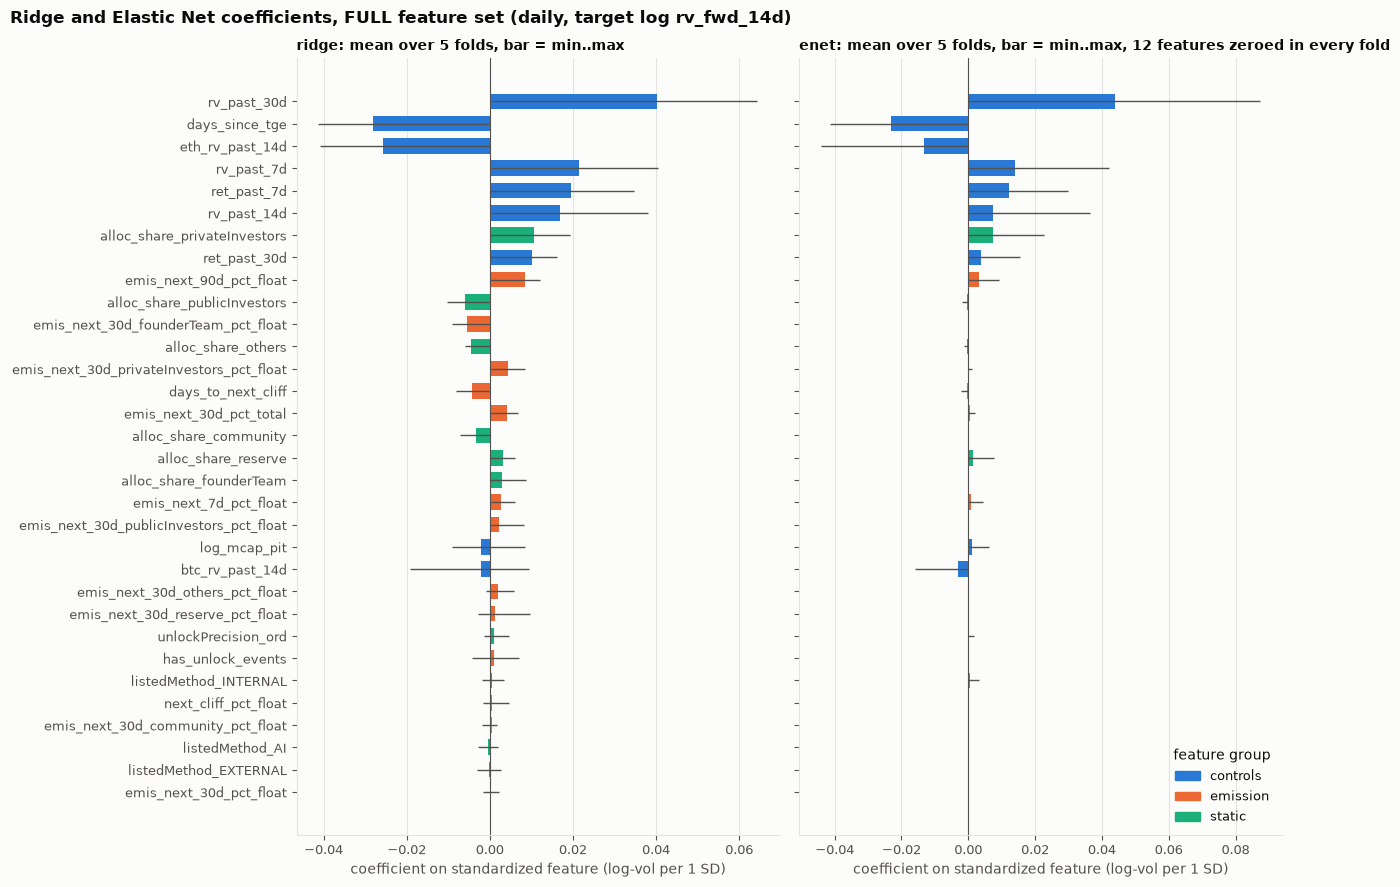

[figure] figures\linear_coefs_full.png


,ridge mean coef_std
feature,
rv_past_30d,0.0403
days_since_tge,-0.0281
eth_rv_past_14d,-0.0256
rv_past_7d,0.0216
ret_past_7d,0.0194
rv_past_14d,0.0170
alloc_share_privateInvestors,0.0105
ret_past_30d,0.0102
emis_next_90d_pct_float,0.0085


In [20]:
def linear_coefficients(df, folds, res):
    """Refit FULL (daily) with each fold's tuned params; standardized coefs."""
    feats = FULL
    X, y = df[feats].to_numpy(float), df["y"].to_numpy()
    rows = []
    for model in LINEAR_MODELS:
        r = res[(res.model == model) & (res.feature_set == "FULL")
                & (res.freq == "daily") & (res.target == TARGETS["y"])
                & (res.subsample == "all")].set_index("fold")
        for k, (tr, _, _) in enumerate(folds, start=1):
            params = json.loads(r.loc[k, "best_params"])
            est = linear_factory(model, feats)(**params).fit(X[tr], y[tr])
            for f, c in zip(feats, est.named_steps[model].coef_):
                rows.append({"model": model, "fold": k, "feature": f,
                             "group": group_of(f), "coef_std": c,
                             "best_params": json.dumps(params, sort_keys=True)})
    coefs = pd.DataFrame(rows)
    if not SMOKE:
        coefs.to_csv(RESULTS_DIR / "linear_coefs.csv", index=False)
    return coefs


def plot_linear_coefs(coefs):
    agg = (coefs.groupby(["model", "feature"])["coef_std"]
                .agg(["mean", "min", "max"]).reset_index())
    order = (agg[agg.model == "ridge"].assign(a=lambda d: d["mean"].abs())
             .sort_values("a")["feature"].tolist())
    fig, axes = plt.subplots(1, 2, figsize=(13, 9), sharey=True)
    for ax, model in zip(axes, LINEAR_MODELS):
        a = agg[agg.model == model].set_index("feature").reindex(order)
        colors = [GROUP_COLOR[group_of(f)] for f in order]
        ax.barh(order, a["mean"], color=colors, height=0.7,
                xerr=[a["mean"] - a["min"], a["max"] - a["mean"]],
                error_kw={"ecolor": INK_2, "elinewidth": 1})
        ax.axvline(0, color=INK_2, linewidth=0.8)
        ax.grid(axis="y", visible=False)
        n_zero = int((coefs[coefs.model == model].groupby("feature")["coef_std"]
                      .apply(lambda s: (s == 0).all())).sum())
        sub = f", {n_zero} features zeroed in every fold" if model == "enet" else ""
        ax.set_title(f"{model}: mean over 5 folds, bar = min..max{sub}",
                     fontsize=10)
        ax.set_xlabel("coefficient on standardized feature (log-vol per 1 SD)")
    axes[1].legend(handles=[Patch(color=c, label=g) for g, c in GROUP_COLOR.items()],
                   title="feature group", loc="lower right")
    fig.suptitle("Ridge and Elastic Net coefficients, FULL feature set "
                 "(daily, target log rv_fwd_14d)", x=0.01, ha="left",
                 fontweight="bold")
    fig.tight_layout()
    savefig(fig, "linear_coefs_full.png")


linear_coefs = linear_coefficients(df_d, folds_d, linear_res)
plot_linear_coefs(linear_coefs)
display(linear_coefs[linear_coefs.model == "ridge"].groupby("feature")["coef_std"]
        .mean().sort_values(key=np.abs, ascending=False).head(12).round(4)
        .to_frame("ridge mean coef_std"))

## 8. Gradient boosting (LightGBM)

Boosted trees fit shallow trees one after another, each correcting the residuals of the previous ones, so they can pick up non-linear interactions between volatility persistence and the emission features. Trees need no scaling. Fixed: row and column subsampling 0.8, `deterministic=True`. Grid (32 configs): `n_estimators in {200, 500}`, `learning_rate in {0.02, 0.05}`, `num_leaves in {7, 15}`, `min_child_samples in {100, 400}`, `reg_lambda in {1, 10}`. As for the Random Forest, the daily runs evaluate a fixed, seeded random subset of the grid (12 configs for the main runs, 6 for robustness runs) and the weekly runs use the full grid.

The grid is deliberately regularized. A first version with `learning_rate` up to 0.1, up to 31 leaves and `min_child_samples` down to 50 overfit the small weekly folds (weekly r2_oos 0.08 CONTROLS / 0.10 FULL, below the pooled train mean, fold 1 at -0.47). The grid is the same for CONTROLS and FULL, so the comparison between them is unaffected.

### 8.1 Runs: main, robustness targets and INTERNAL subsample

In [24]:
LGBM_NAME = "lightgbm"
LGBM_GRID = {"n_estimators": [200, 500],
             "learning_rate": [0.02, 0.05],
             "num_leaves": [7, 15],
             "min_child_samples": [100, 400],
             "reg_lambda": [1, 10]}
LGBM_BUDGET = {"daily_main": 12, "daily_robust": 6, "weekly": None}
if SMOKE:
    LGBM_GRID = {"n_estimators": [100], "learning_rate": [0.05],
                 "num_leaves": [7, 15], "min_child_samples": [200],
                 "reg_lambda": [1]}
    LGBM_BUDGET = {k: None for k in LGBM_BUDGET}


def lgbm_factory(**params) -> Pipeline:
    return Pipeline([("lgbm", LGBMRegressor(
        subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
        deterministic=True, force_row_wise=True,  # reproducible with n_jobs=-1
        random_state=RANDOM_STATE, n_jobs=-1, verbose=-1, **params))])


def run_lgbm(df, folds, fs, freq, budget, **kw):
    done = finished_run(LGBM_NAME, folds, fs, freq, **kw)
    if done is not None:
        return done
    return run_model(LGBM_NAME, lgbm_factory, df, folds, fs, LGBM_GRID, freq,
                     max_configs=LGBM_BUDGET[budget], save=not SMOKE, **kw)


lgbm_results = []
for freq, (df, folds) in data.items():
    for fs in ("CONTROLS", "FULL"):
        lgbm_results.append(run_lgbm(df, folds, fs, freq,
                                     "weekly" if freq == "weekly" else "daily_main"))
df_d, folds_d = data["daily"]
for target in ("y_14d_parkinson", "y_7d", "y_30d"):
    for fs in ("CONTROLS", "FULL"):
        lgbm_results.append(run_lgbm(df_d, folds_d, fs, "daily", "daily_robust",
                                     target=target))
sub = df_d[df_d["listedMethod_INTERNAL"] == 1].reset_index(drop=True)
sub_folds = make_folds(sub, verbose=False)
for fs in ("CONTROLS", "FULL"):
    lgbm_results.append(run_lgbm(sub, sub_folds, fs, "daily", "daily_robust",
                                 subsample="INTERNAL"))
lgbm_res = pd.concat(lgbm_results, ignore_index=True)

print("LightGBM mean over folds:")
display(lgbm_res.groupby(["freq", "target", "subsample", "feature_set"], sort=False)
        [["rmse", "mae", "r2_oos", "spearman"]].mean().round(4))

[lightgbm|CONTROLS_daily] found in results/lightgbm.csv, reusing (mean rmse 0.4559, r2_oos +0.2249); set NB_FRESH=1 to recompute
[lightgbm|FULL_daily] found in results/lightgbm.csv, reusing (mean rmse 0.4530, r2_oos +0.2295); set NB_FRESH=1 to recompute
[lightgbm|CONTROLS_weekly] found in results/lightgbm.csv, reusing (mean rmse 0.4634, r2_oos +0.1637); set NB_FRESH=1 to recompute
[lightgbm|FULL_weekly] found in results/lightgbm.csv, reusing (mean rmse 0.4649, r2_oos +0.1677); set NB_FRESH=1 to recompute
[lightgbm|CONTROLS_daily_log_rv_fwd_14d_parkinson] found in results/lightgbm.csv, reusing (mean rmse 0.4440, r2_oos +0.3213); set NB_FRESH=1 to recompute
[lightgbm|FULL_daily_log_rv_fwd_14d_parkinson] found in results/lightgbm.csv, reusing (mean rmse 0.4409, r2_oos +0.3308); set NB_FRESH=1 to recompute
[lightgbm|CONTROLS_daily_log_rv_fwd_7d] found in results/lightgbm.csv, reusing (mean rmse 0.5129, r2_oos +0.1894); set NB_FRESH=1 to recompute
[lightgbm|FULL_daily_log_rv_fwd_7d] found i

rmse     mae  r2_oos  spearman
freq   target                   subsample feature_set                                  
daily  log_rv_fwd_14d           all       CONTROLS     0.4559  0.3677  0.2249    0.2787
                                          FULL         0.4530  0.3653  0.2295    0.2879
weekly log_rv_fwd_14d           all       CONTROLS     0.4634  0.3700  0.1637    0.2599
                                          FULL         0.4649  0.3727  0.1677    0.2863
daily  log_rv_fwd_14d_parkinson all       CONTROLS     0.4440  0.3456  0.3213    0.3602
                                          FULL         0.4409  0.3446  0.3308    0.3745
       log_rv_fwd_7d            all       CONTROLS     0.5129  0.4037  0.1894    0.3010
                                          FULL         0.5108  0.4010  0.1915    0.3023
       log_rv_fwd_30d           all       CONTROLS     0.3994  0.3285  0.3575    0.3164
                                          FULL         0.3932  0.3236  0.3742    0.3246
       log_rv_fwd_14d           INTERNAL  CONTROLS     0.4528  0.3661  0.2197    0.2807
                                          FULL         0.4478  0.3613  0.2325    0.2987

### 8.2 Feature importance (last fold, FULL config)

Gain importance of the last fold's tuned FULL model on the daily panel: the share of the total loss reduction contributed by splits on each feature while the trees were grown (training set). The legend gives the share of gain per feature group.

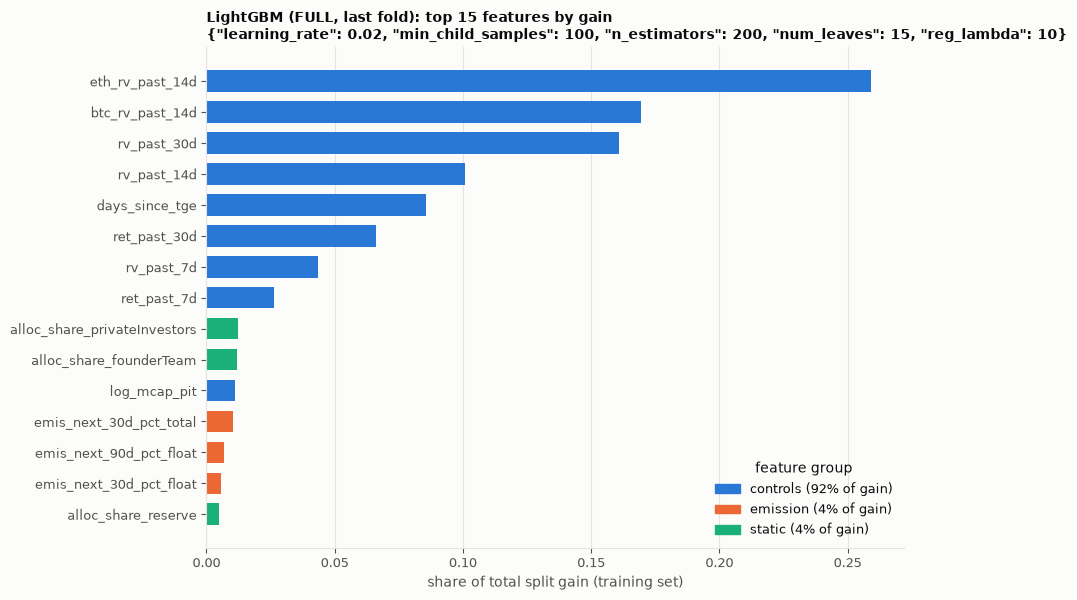

[figure] figures\lgbm_importance.png


,feature,group,gain,gain_share
6,eth_rv_past_14d,controls,23663.2637,0.2590
5,btc_rv_past_14d,controls,15493.5617,0.1696
2,rv_past_30d,controls,14707.7311,0.1610
1,rv_past_14d,controls,9220.3550,0.1009
8,days_since_tge,controls,7827.0631,0.0857
4,ret_past_30d,controls,6047.3034,0.0662
0,rv_past_7d,controls,3956.3564,0.0433
3,ret_past_7d,controls,2410.9695,0.0264
23,alloc_share_privateInvestors,static,1135.5165,0.0124
22,alloc_share_founderTeam,static,1095.2852,0.0120


In [25]:
def lgbm_importance(df, folds, res):
    """Gain importance of the last-fold FULL (daily) model, refit with its
    tuned params. Gain is measured on the training set, not on test."""
    feats = FULL
    tr = folds[-1][0]
    r = res[(res.feature_set == "FULL") & (res.freq == "daily")
            & (res.target == TARGETS["y"]) & (res.subsample == "all")
            & (res.fold == len(folds))]
    params = json.loads(r.iloc[0]["best_params"])
    est = lgbm_factory(**params).fit(df[feats].to_numpy(float)[tr],
                                     df["y"].to_numpy()[tr])
    gain = est.named_steps["lgbm"].booster_.feature_importance("gain")
    imp = pd.DataFrame({"feature": feats, "group": [group_of(f) for f in feats],
                        "gain": gain, "gain_share": gain / gain.sum()})
    imp = imp.sort_values("gain_share", ascending=False)
    if not SMOKE:
        imp.to_csv(RESULTS_DIR / "lgbm_importance.csv", index=False)
    return imp, params


def plot_lgbm_importance(imp, params):
    top = imp.head(15).iloc[::-1]
    fig, ax = plt.subplots(figsize=(9, 6.5))
    ax.barh(top["feature"], top["gain_share"],
            color=[GROUP_COLOR[g] for g in top["group"]], height=0.7)
    ax.grid(axis="y", visible=False)
    ax.set_xlabel("share of total split gain (training set)")
    shares = imp.groupby("group")["gain_share"].sum()
    ax.legend(handles=[Patch(color=c, label=f"{g} ({shares.get(g, 0):.0%} of gain)")
                       for g, c in GROUP_COLOR.items()],
              title="feature group", loc="lower right")
    ax.set_title("LightGBM (FULL, last fold): top 15 features by gain\n"
                 f"{json.dumps(params, sort_keys=True)}", fontsize=10)
    savefig(fig, "lgbm_importance.png")


lgbm_imp, lgbm_params = lgbm_importance(df_d, folds_d, lgbm_res)
plot_lgbm_importance(lgbm_imp, lgbm_params)
display(lgbm_imp.head(15).round(4))

## 9. Comparison across models

Every per-fold results CSV in `results/` is aggregated into one table (mean and std across folds by model, feature set, panel frequency, target and subsample). The chart shows `r2_oos` against persistence for controls-only vs the full feature set.


In [26]:
METRICS = ["rmse", "mae", "r2_oos", "spearman", "rmse_level"]
REQUIRED = set(RESULT_COLUMNS) - {"subsample"}
BASELINES = ["persistence", "train_mean"]


def read_results() -> pd.DataFrame:
    frames = []
    for path in sorted(RESULTS_DIR.glob("*.csv")):
        head = pd.read_csv(path, nrows=0)
        if not REQUIRED.issubset(head.columns):
            continue  # eda summary, importances, validation curves, ...
        d = pd.read_csv(path)
        if "subsample" not in d.columns:
            d["subsample"] = "all"
        d["subsample"] = d["subsample"].fillna("all")
        frames.append(d)
        print(f"[04_compare] {path.name}: {len(d)} fold rows, "
              f"models {sorted(d['model'].unique())}")
    return pd.concat(frames, ignore_index=True)

def plot(table):
    main_t = table[(table.target == TARGETS["y"]) & (table.subsample == "all")]
    models = [m for m in main_t["model"].unique() if m not in BASELINES]
    sets = [("CONTROLS", "controls only", PALETTE[0]),
            ("FULL", "controls + emission + static (FULL)", PALETTE[1])]
    fig, axes = plt.subplots(1, 2, figsize=(max(9, 2.2 * len(models) + 5), 5),
                             sharey=True)
    for ax, freq in zip(axes, ("daily", "weekly")):
        t = main_t[main_t.freq == freq].set_index(["model", "feature_set"])
        x = np.arange(len(models))
        for i, (fs, label, color) in enumerate(sets):
            mean = [t["r2_oos_mean"].get((m, fs), np.nan) for m in models]
            std = [t["r2_oos_std"].get((m, fs), np.nan) for m in models]
            ax.bar(x + (i - 0.5) * 0.38, mean, width=0.36, yerr=std, color=color,
                   label=label, error_kw={"ecolor": INK_2, "elinewidth": 1})
            for xi, v in zip(x, mean):
                if np.isfinite(v):
                    ax.text(xi + (i - 0.5) * 0.38, 0.005, f"{v:.3f}", ha="center",
                            va="bottom", fontsize=8, color="white",
                            fontweight="bold")
        ax.axhline(0, color=INK, linestyle="--", linewidth=1.2,
                   label="persistence baseline (0 by construction)")
        if ("train_mean", "NONE") in t.index:
            tm = t.loc[("train_mean", "NONE"), "r2_oos_mean"]
            ax.axhline(tm, color=INK_2, linestyle=":", linewidth=1.5,
                       label="pooled train-mean baseline")
            ax.text(-0.58, tm, f"{tm:.3f}", ha="left", va="bottom", fontsize=8,
                    color=INK_2)
        ax.set_xticks(x)
        ax.set_xticklabels(models)
        ax.set_xlim(-0.6, len(models) - 0.4)
        ax.grid(axis="x", visible=False)
        ax.set_title(f"{freq} panel", fontsize=10)
    axes[0].set_ylabel("r2_oos vs persistence (mean of 5 folds, bar = +/- 1 std)")
    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="lower center", ncol=2,
               bbox_to_anchor=(0.5, -0.1))
    fig.suptitle("Out-of-sample R2 by model: controls only vs full feature set "
                 "(target log rv_fwd_14d)", x=0.01, ha="left", fontweight="bold")
    fig.tight_layout()
    savefig(fig, "compare_r2_oos.png")


[04_compare] baselines.csv: 60 fold rows, models ['persistence', 'train_mean']
[04_compare] enet.csv: 60 fold rows, models ['enet']
[04_compare] knn.csv: 30 fold rows, models ['knn']
[04_compare] lightgbm.csv: 60 fold rows, models ['lightgbm']


[04_compare] rf.csv: 45 fold rows, models ['rf']
[04_compare] ridge.csv: 60 fold rows, models ['ridge']


,model,feature_set,freq,target,subsample,n_folds,rmse_mean,rmse_std,mae_mean,mae_std,r2_oos_mean,r2_oos_std,spearman_mean,spearman_std,rmse_level_mean,rmse_level_std
22,enet,CONTROLS,daily,log_rv_fwd_14d,INTERNAL,5,0.4401,0.0709,0.3519,0.0608,0.2641,0.1442,0.3319,0.1358,0.5092,0.0920
23,enet,FULL,daily,log_rv_fwd_14d,INTERNAL,5,0.4401,0.0709,0.3523,0.0611,0.2640,0.1447,0.3388,0.1368,0.5090,0.0919
40,lightgbm,CONTROLS,daily,log_rv_fwd_14d,INTERNAL,5,0.4528,0.0729,0.3661,0.0599,0.2197,0.1639,0.2807,0.1358,0.5184,0.1011
41,lightgbm,FULL,daily,log_rv_fwd_14d,INTERNAL,5,0.4478,0.0696,0.3613,0.0570,0.2325,0.1750,0.2987,0.1155,0.5147,0.0946
10,persistence,NONE,daily,log_rv_fwd_14d,INTERNAL,5,0.5215,0.1098,0.4058,0.1069,0.0000,0.0000,0.2457,0.1804,0.6616,0.1271
49,rf,CONTROLS,daily,log_rv_fwd_14d,INTERNAL,5,0.4416,0.0744,0.3530,0.0624,0.2597,0.1511,0.3083,0.1131,0.5110,0.0967
50,rf,FULL,daily,log_rv_fwd_14d,INTERNAL,5,0.4371,0.0768,0.3505,0.0665,0.2763,0.1473,0.3342,0.1101,0.5073,0.0936
61,ridge,CONTROLS,daily,log_rv_fwd_14d,INTERNAL,5,0.4368,0.0717,0.3495,0.0618,0.2727,0.1579,0.3486,0.1373,0.5059,0.0903
62,ridge,FULL,daily,log_rv_fwd_14d,INTERNAL,5,0.4358,0.0724,0.3488,0.0626,0.2776,0.1512,0.3511,0.1340,0.5055,0.0918
11,train_mean,NONE,daily,log_rv_fwd_14d,INTERNAL,5,0.4641,0.0970,0.3756,0.0852,0.1792,0.2310,NaN,NaN,0.5251,0.0922


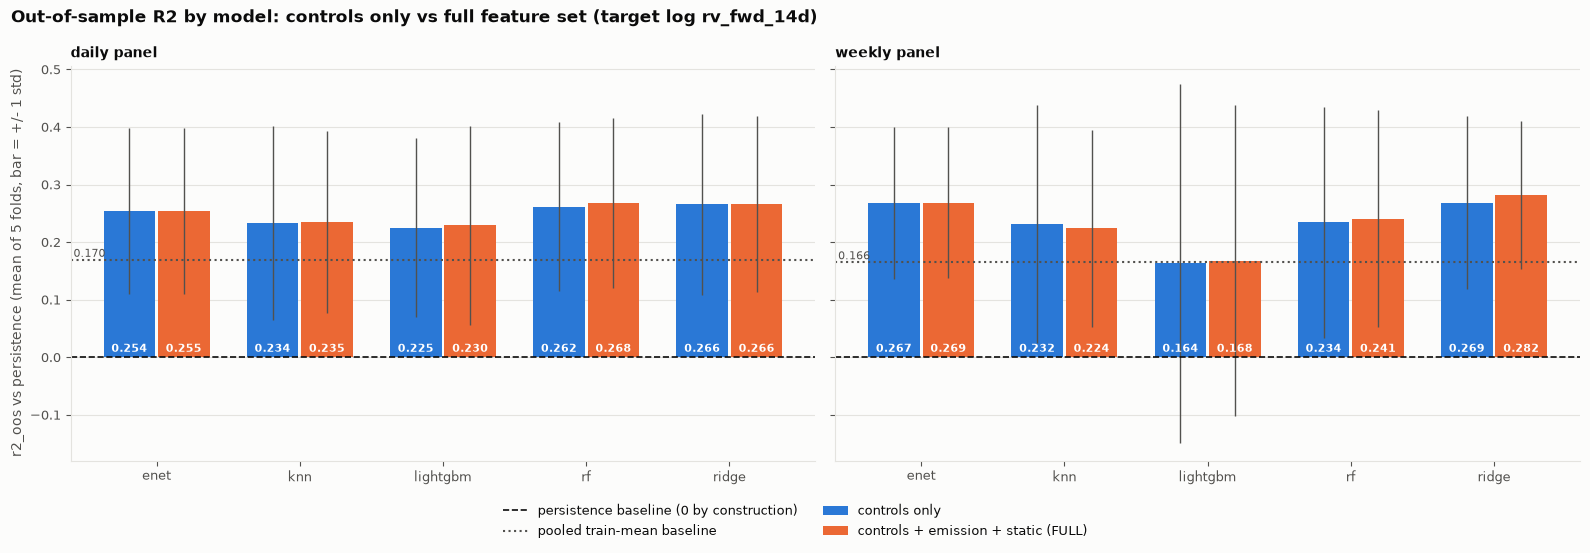

[figure] figures\compare_r2_oos.png


In [27]:
if SMOKE:
    res_all = pd.concat([baseline_res, knn_res, rf_res, linear_res, lgbm_res], ignore_index=True)
else:
    res_all = read_results()          # every per-fold results CSV in results/
keys = ["model", "feature_set", "freq", "target", "subsample"]
table = res_all.groupby(keys, sort=False)[METRICS].agg(["mean", "std"])
table.columns = [f"{m}_{s}" for m, s in table.columns]
table.insert(0, "n_folds", res_all.groupby(keys, sort=False)["fold"].nunique())
table = table.reset_index().sort_values(
    ["target", "subsample", "freq", "model", "feature_set"],
    key=lambda s: s.map({"daily": 0, "weekly": 1}) if s.name == "freq" else s)
if not SMOKE:
    table.to_csv(RESULTS_DIR / "comparison_table.csv", index=False)
with pd.option_context("display.max_rows", 200):
    display(table.round(4))
plot(table)


In [28]:
main_t = table[(table.target == TARGETS["y"]) & (table.subsample == "all")]
piv = main_t.pivot(index=["freq", "model"], columns="feature_set", values="r2_oos_mean")
piv["delta_FULL_minus_CONTROLS"] = piv["FULL"] - piv["CONTROLS"]
print("Headline: out-of-sample R2 vs persistence (mean of 5 folds), target log rv_fwd_14d")
display(piv.round(4))
rmse = main_t.pivot(index=["freq", "model"], columns="feature_set", values="rmse_mean")
rmse["delta_FULL_minus_CONTROLS"] = rmse["FULL"] - rmse["CONTROLS"]
print("RMSE in log-vol space (lower is better)")
display(rmse.round(4))


Headline: out-of-sample R2 vs persistence (mean of 5 folds), target log rv_fwd_14d


feature_set         CONTROLS  CONTROLS+EMIS5    FULL    NONE  delta_FULL_minus_CONTROLS
freq   model                                                                           
daily  enet           0.2539             NaN  0.2549     NaN                     0.0009
       knn            0.2337          0.2401  0.2350     NaN                     0.0014
       lightgbm       0.2249             NaN  0.2295     NaN                     0.0046
       persistence       NaN             NaN     NaN  0.0000                        NaN
       rf             0.2617             NaN  0.2681     NaN                     0.0064
       ridge          0.2659             NaN  0.2664     NaN                     0.0006
       train_mean        NaN             NaN     NaN  0.1698                        NaN
weekly enet           0.2673             NaN  0.2688     NaN                     0.0015
       knn            0.2322          0.2386  0.2245     NaN                    -0.0078
       lightgbm       0.1637             NaN  0.1677     NaN                     0.0040
       persistence       NaN             NaN     NaN  0.0000                        NaN
       rf             0.2343             NaN  0.2410     NaN                     0.0067
       ridge          0.2687             NaN  0.2822     NaN                     0.0135
       train_mean        NaN             NaN     NaN  0.1656                        NaN

RMSE in log-vol space (lower is better)


feature_set         CONTROLS  CONTROLS+EMIS5    FULL    NONE  delta_FULL_minus_CONTROLS
freq   model                                                                           
daily  enet           0.4471             NaN  0.4468     NaN                    -0.0003
       knn            0.4526          0.4507  0.4538     NaN                     0.0011
       lightgbm       0.4559             NaN  0.4530     NaN                    -0.0029
       persistence       NaN             NaN     NaN  0.5269                        NaN
       rf             0.4451             NaN  0.4431     NaN                    -0.0021
       ridge          0.4428             NaN  0.4428     NaN                     0.0000
       train_mean        NaN             NaN     NaN  0.4713                        NaN
weekly enet           0.4450             NaN  0.4445     NaN                    -0.0005
       knn            0.4534          0.4524  0.4576     NaN                     0.0042
       lightgbm       0.4634             NaN  0.4649     NaN                     0.0015
       persistence       NaN             NaN     NaN  0.5274                        NaN
       rf             0.4510             NaN  0.4500     NaN                    -0.0010
       ridge          0.4432             NaN  0.4408     NaN                    -0.0024
       train_mean        NaN             NaN     NaN  0.4733                        NaN

## 10. Error analysis and practical relevance

A comparison is more than a leaderboard, so this section asks **which mistakes remain** and whether any improvement is **useful for a decision**. It reads the saved test-set predictions of the main daily runs (nothing is refit or retuned), so every forecast, including persistence and the train mean, is scored on exactly the same test rows.

- RMSE and bias by ex-ante subgroup: 30-day unlock pressure, a cliff unlock within 14 days, token age, trailing-volatility quintile and BTC regime. If unlock features carried signal, FULL should beat CONTROLS where unlocks are heavy.
- Calibration and the errors by quintile of realized volatility (grouping by the outcome describes the errors; it is never a feature).
- Errors in annualized-volatility units and the share of forecasts off by more than 2x, the scale a risk desk works in.
- One illustrative depth-3 regression tree on FULL features, fit on the last fold's training rows only, to show which variables a tree splits on (it is not a competing model).

In [29]:
from sklearn.tree import DecisionTreeRegressor, plot_tree

RUNS = {  # label -> (model, feature set)
    "Ridge CONTROLS": ("ridge", "CONTROLS"), "Ridge FULL": ("ridge", "FULL"),
    "RF CONTROLS": ("rf", "CONTROLS"), "RF FULL": ("rf", "FULL"),
    "KNN CONTROLS": ("knn", "CONTROLS"), "KNN FULL": ("knn", "FULL"),
    "EN CONTROLS": ("enet", "CONTROLS"), "EN FULL": ("enet", "FULL"),
    "LGBM CONTROLS": ("lightgbm", "CONTROLS"), "LGBM FULL": ("lightgbm", "FULL"),
}
SHOW = ["Persistence", "Train mean", "Ridge CONTROLS", "RF CONTROLS", "RF FULL"]
BIG_MISS = np.log(2.0)   # forecast off by more than a factor of 2


def test_frame(df, folds) -> pd.DataFrame:
    """Every test row once, with ex-ante descriptors and all forecasts."""
    rows = []
    for k, (tr, _, te) in enumerate(folds, start=1):
        part = df.iloc[te][["token_id", "date", "y", "rv_past_14d", "btc_rv_past_14d",
                            "days_since_tge", "days_to_next_cliff",
                            "emis_next_30d_pct_float"]].copy()
        part["fold"] = k
        part["Persistence"] = np.log(part["rv_past_14d"])
        part["Train mean"] = df["y"].iloc[tr].mean()
        rows.append(part)
    out = pd.concat(rows, ignore_index=True)
    for label, (m, fs) in RUNS.items():
        p = pd.read_parquet(RESULTS_DIR / f"preds_{m}_{fs}_daily.parquet")
        p = p.rename(columns={"y_pred": label})[["token_id", "date", "fold", label]]
        out = out.merge(p, on=["token_id", "date", "fold"], how="left", validate="1:1")
    missing = out[list(RUNS)].isna().sum()
    assert missing.sum() == 0, f"predictions missing for some test rows:\n{missing}"

    emis = np.expm1(out["emis_next_30d_pct_float"])          # share of float, level
    out["unlock_group"] = pd.cut(emis, [-np.inf, 0.005, 0.02, 0.05, np.inf],
                                 labels=["<0.5%", "0.5-2%", "2-5%", ">5%"])
    out["cliff_14d"] = np.where(out["days_to_next_cliff"] <= 14, "cliff in 14d", "no cliff in 14d")
    out["age_group"] = pd.cut(out["days_since_tge"], [-np.inf, 365, 730, np.inf],
                              labels=["<1y", "1-2y", ">2y"])
    out["trail_vol_q"] = pd.qcut(out["rv_past_14d"], 5, labels=[f"Q{i}" for i in range(1, 6)])
    out["btc_regime"] = pd.qcut(out["btc_rv_past_14d"], 3, labels=["calm", "mid", "stressed"])
    out["realized_q"] = pd.qcut(out["y"], 5, labels=[f"Q{i}" for i in range(1, 6)])
    return out


def group_table(t: pd.DataFrame) -> pd.DataFrame:
    labels = ["Persistence", "Train mean"] + list(RUNS)
    recs = []
    for dim in ["unlock_group", "cliff_14d", "age_group", "trail_vol_q", "btc_regime", "realized_q"]:
        for g, sub in t.groupby(dim, observed=True):
            r = {"dimension": dim, "group": str(g), "n": len(sub), "share": len(sub) / len(t)}
            for lab in labels:
                err = sub["y"] - sub[lab]
                r[f"rmse|{lab}"] = float(np.sqrt(np.mean(err ** 2)))
                r[f"bias|{lab}"] = float(np.mean(err))   # >0: forecast too low
            for m in ["Ridge", "RF", "KNN", "EN", "LGBM"]:
                r[f"delta_rmse|{m}"] = r[f"rmse|{m} FULL"] - r[f"rmse|{m} CONTROLS"]
            recs.append(r)
    return pd.DataFrame(recs)


def level_summary(t: pd.DataFrame) -> pd.DataFrame:
    """Errors in annualized-vol units, the scale a risk desk works in."""
    rv = np.exp(t["y"])
    recs = []
    for lab in ["Persistence", "Train mean"] + list(RUNS):
        f = np.exp(t[lab])
        err = t["y"] - t[lab]
        recs.append({"forecast": lab,
                     "median_abs_vol_error": float(np.median(np.abs(f - rv))),
                     "median_abs_pct_error": float(np.median(np.abs(f / rv - 1))),
                     "share_within_25pct": float(np.mean(np.abs(f / rv - 1) <= 0.25)),
                     "share_off_by_2x": float(np.mean(np.abs(err) > BIG_MISS)),
                     "share_big_miss_underforecast": float(np.mean(err[np.abs(err) > BIG_MISS] > 0)),
                     "rmse_log": float(np.sqrt(np.mean(err ** 2)))})
    return pd.DataFrame(recs)


def big_misses(t: pd.DataFrame, label: str = "Ridge CONTROLS") -> pd.DataFrame:
    """Who the remaining 2x misses are, against all other test rows."""
    miss = np.abs(t["y"] - t[label]) > BIG_MISS
    emis = np.expm1(t["emis_next_30d_pct_float"])
    recs = []
    for name, m in (("2x miss", miss), ("other rows", ~miss)):
        s = t[m]
        recs.append({"rows": name, "n": int(m.sum()),
                     "median_days_since_tge": float(s["days_since_tge"].median()),
                     "median_rv_past_14d": float(s["rv_past_14d"].median()),
                     "median_rv_fwd_14d": float(np.exp(s["y"]).median()),
                     "median_unlock_30d_pct_float": float(emis[m].median()),
                     "share_cliff_in_14d": float((s["days_to_next_cliff"] <= 14).mean()),
                     "share_young_lt_1y": float((s["days_since_tge"] < 365).mean())})
    return pd.DataFrame(recs)


def plot_calibration(t: pd.DataFrame) -> None:
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
    ax = axes[0]
    for lab, col in (("Persistence", INK_2), ("Ridge CONTROLS", PALETTE[0]), ("RF FULL", PALETTE[1])):
        b = pd.qcut(t[lab], 10, duplicates="drop")
        g = t.groupby(b, observed=True).agg(pred=(lab, "mean"), real=("y", "mean"))
        ax.plot(np.exp(g["pred"]), np.exp(g["real"]), "o-", color=col, label=lab)
    lo, hi = 0.3, 2.0
    ax.plot([lo, hi], [lo, hi], ls="--", color="0.6", lw=1)
    ax.set_xlim(lo, hi); ax.set_ylim(lo, hi)
    ax.set_xlabel("forecast rv_fwd_14d (decile mean)"); ax.set_ylabel("realized rv_fwd_14d")
    ax.set_title("Calibration: forecast deciles vs realized")
    ax.legend(loc="upper left")
    ax = axes[1]
    q = t.groupby("realized_q", observed=True)
    x = np.arange(5)
    for i, (lab, col) in enumerate((("Persistence", INK_2), ("Ridge CONTROLS", PALETTE[0]), ("RF FULL", PALETTE[1]))):
        bias = q.apply(lambda s: float(np.mean(s["y"] - s[lab])))
        ax.bar(x + (i - 1) * 0.27, bias.to_numpy(), width=0.27, color=col, label=lab)
    ax.axhline(0, color=INK_2, lw=0.8)
    ax.set_xticks(x, [f"Q{i}\n{np.exp(t.loc[t.realized_q == f'Q{i}', 'y']).median():.2f}" for i in range(1, 6)])
    ax.set_xlabel("quintile of realized rv_fwd_14d (median)")
    ax.set_ylabel("mean error, log (realized - forecast)")
    ax.set_title("Remaining mistakes: too high when calm, too low when volatile")
    ax.grid(axis="x", visible=False)
    fig.tight_layout()
    savefig(fig, "errors_calibration.png")


def plot_groups(g: pd.DataFrame) -> None:
    dims = [("unlock_group", "30-day unlock pressure (share of float)"),
            ("cliff_14d", "cliff unlock within 14 days"),
            ("age_group", "token age"), ("btc_regime", "BTC volatility regime")]
    fig, axes = plt.subplots(1, 4, figsize=(15, 4.4), sharey=True)
    cols = {"Persistence": INK_2, "Train mean": "#B7BDC7", "Ridge CONTROLS": PALETTE[0],
            "RF CONTROLS": "#7FB0E6", "RF FULL": PALETTE[1]}
    for ax, (dim, title) in zip(axes, dims):
        sub = g[g.dimension == dim]
        x = np.arange(len(sub))
        w = 0.8 / len(SHOW)
        for i, lab in enumerate(SHOW):
            ax.bar(x + (i - (len(SHOW) - 1) / 2) * w, sub[f"rmse|{lab}"], width=w,
                   color=cols[lab], label=lab)
        ax.set_xticks(x, [f"{gr}\n(n={n:,})" for gr, n in zip(sub.group, sub.n)], fontsize=8)
        ax.set_title(title, fontsize=10)
        ax.grid(axis="x", visible=False)
    axes[0].set_ylabel("test RMSE (log vol)")
    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="lower center", ncol=len(SHOW), fontsize=9)
    fig.suptitle("Test RMSE by ex-ante subgroup (daily panel, all 5 folds pooled)",
                 x=0.01, ha="left", fontweight="bold")
    fig.tight_layout(rect=(0, 0.07, 1, 1))
    savefig(fig, "errors_by_group.png")


def plot_tree_last_fold(df, folds) -> list[str]:
    tr = folds[-1][0]
    feats = FEATURE_SETS["FULL"]
    tree = DecisionTreeRegressor(max_depth=3, min_samples_leaf=500,
                                 random_state=RANDOM_STATE)
    tree.fit(df[feats].iloc[tr], df["y"].iloc[tr])
    fig, ax = plt.subplots(figsize=(16, 6.5))
    plot_tree(tree, feature_names=feats, filled=False, impurity=False, rounded=True,
              precision=2, fontsize=8, ax=ax)
    ax.set_title("Illustrative depth-3 regression tree on FULL features "
                 "(last fold, training rows only; leaf value = mean log rv_fwd_14d)")
    savefig(fig, "tree_depth3_full.png")
    used = [feats[i] for i in tree.tree_.feature if i >= 0]
    return used


73,414 test rows, 176 tokens; every forecast scored on the same rows


Test RMSE by subgroup; delta = FULL minus CONTROLS (negative = unlock features help)


,dimension,group,n,rmse|Persistence,rmse|Train mean,rmse|Ridge CONTROLS,rmse|RF CONTROLS,rmse|RF FULL,delta_rmse|Ridge,delta_rmse|RF,delta_rmse|LGBM
0,unlock_group,<0.5%,28675,0.5408,0.5075,0.4625,0.4609,0.4556,-0.0043,-0.0053,-0.0053
1,unlock_group,0.5-2%,16329,0.5348,0.4814,0.4458,0.4491,0.4434,-0.0035,-0.0056,-0.0049
2,unlock_group,2-5%,18464,0.5400,0.4629,0.4418,0.4493,0.4536,0.0028,0.0043,0.0002
3,unlock_group,>5%,9946,0.5374,0.4557,0.4379,0.4422,0.4465,0.0126,0.0043,0.0001
4,cliff_14d,cliff in 14d,12125,0.5133,0.4569,0.4250,0.4341,0.4371,0.0069,0.0030,-0.0009
5,cliff_14d,no cliff in 14d,61289,0.5437,0.4891,0.4552,0.4565,0.4539,-0.0014,-0.0025,-0.0035
6,age_group,<1y,18173,0.5491,0.4683,0.4540,0.4612,0.4624,0.0043,0.0012,-0.0050
7,age_group,1-2y,20222,0.5194,0.4485,0.4266,0.4368,0.4319,-0.0006,-0.0049,-0.0046
8,age_group,>2y,35019,0.5444,0.5108,0.4617,0.4576,0.4562,-0.0021,-0.0014,-0.0013
9,trail_vol_q,Q1,14683,0.6080,0.6005,0.5079,0.4944,0.5046,-0.0009,0.0102,0.0012


Errors in volatility units


,forecast,median_abs_vol_error,median_abs_pct_error,share_within_25pct,share_off_by_2x,share_big_miss_underforecast,rmse_log
0,Persistence,0.258,0.316,0.408,0.182,0.487,0.539
1,Train mean,0.301,0.346,0.377,0.145,0.303,0.484
2,Ridge CONTROLS,0.269,0.318,0.407,0.119,0.379,0.450
3,Ridge FULL,0.269,0.320,0.406,0.118,0.377,0.450
4,RF CONTROLS,0.267,0.320,0.407,0.120,0.397,0.453
5,RF FULL,0.271,0.323,0.403,0.118,0.392,0.451
6,KNN CONTROLS,0.270,0.323,0.406,0.128,0.369,0.461
7,KNN FULL,0.282,0.333,0.389,0.128,0.346,0.464
8,EN CONTROLS,0.271,0.323,0.403,0.123,0.383,0.454
9,EN FULL,0.272,0.324,0.403,0.123,0.384,0.454


Rows the best model (Ridge CONTROLS) misses by more than 2x, against all other rows


,rows,n,median_days_since_tge,median_rv_past_14d,median_rv_fwd_14d,median_unlock_30d_pct_float,share_cliff_in_14d,share_young_lt_1y
0,2x miss,8720,739.0,0.769,0.480,0.009,0.139,0.260
1,other rows,64694,685.0,0.841,0.834,0.011,0.169,0.245


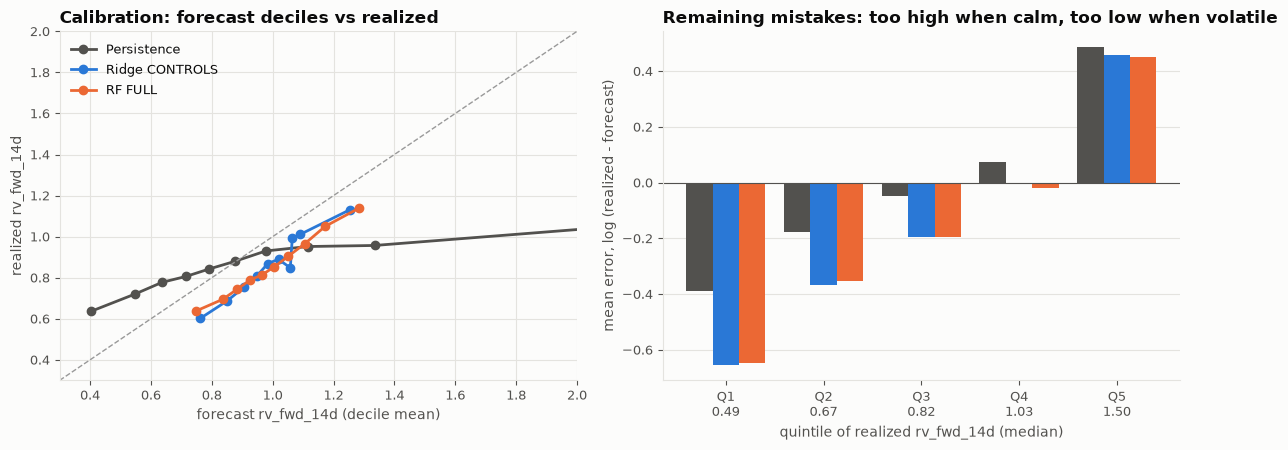

[figure] figures\errors_calibration.png


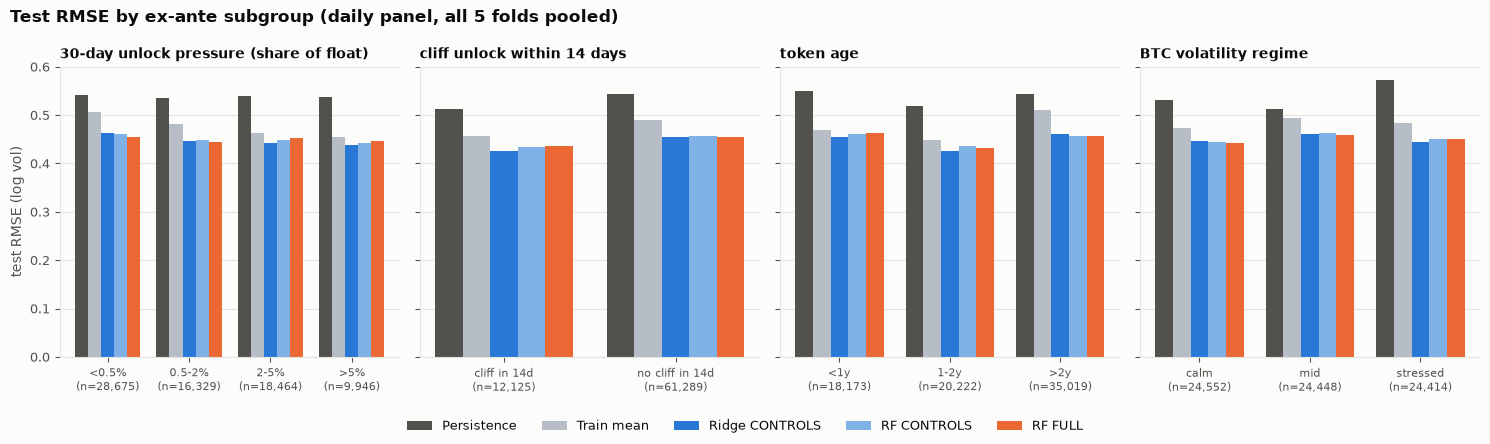

[figure] figures\errors_by_group.png


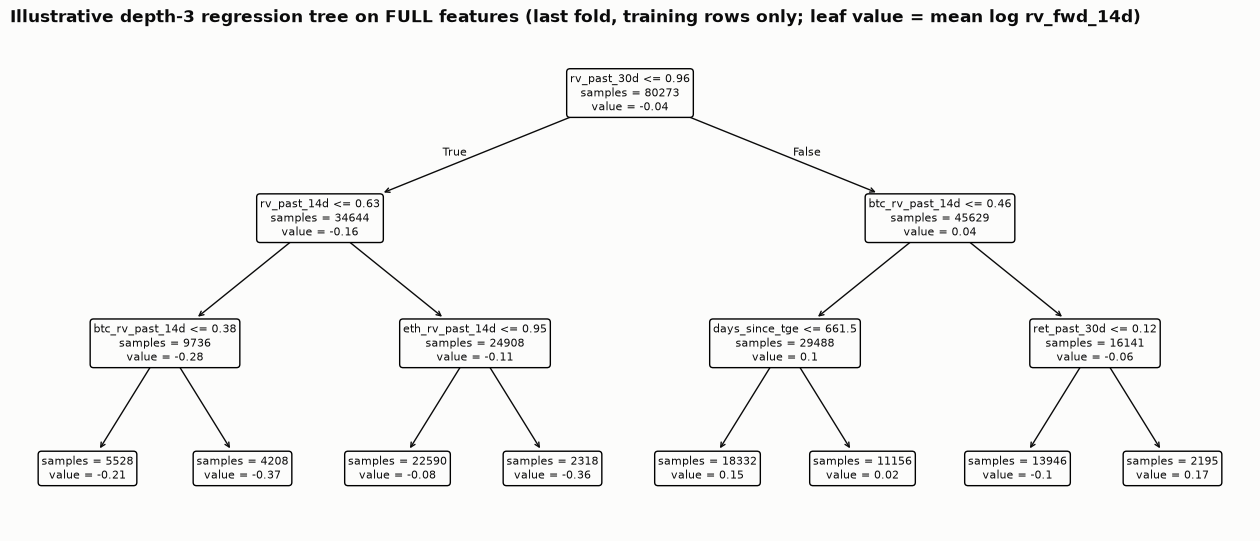

[figure] figures\tree_depth3_full.png
depth-3 tree splits on: rv_past_30d, rv_past_14d, btc_rv_past_14d, eth_rv_past_14d, days_since_tge, ret_past_30d


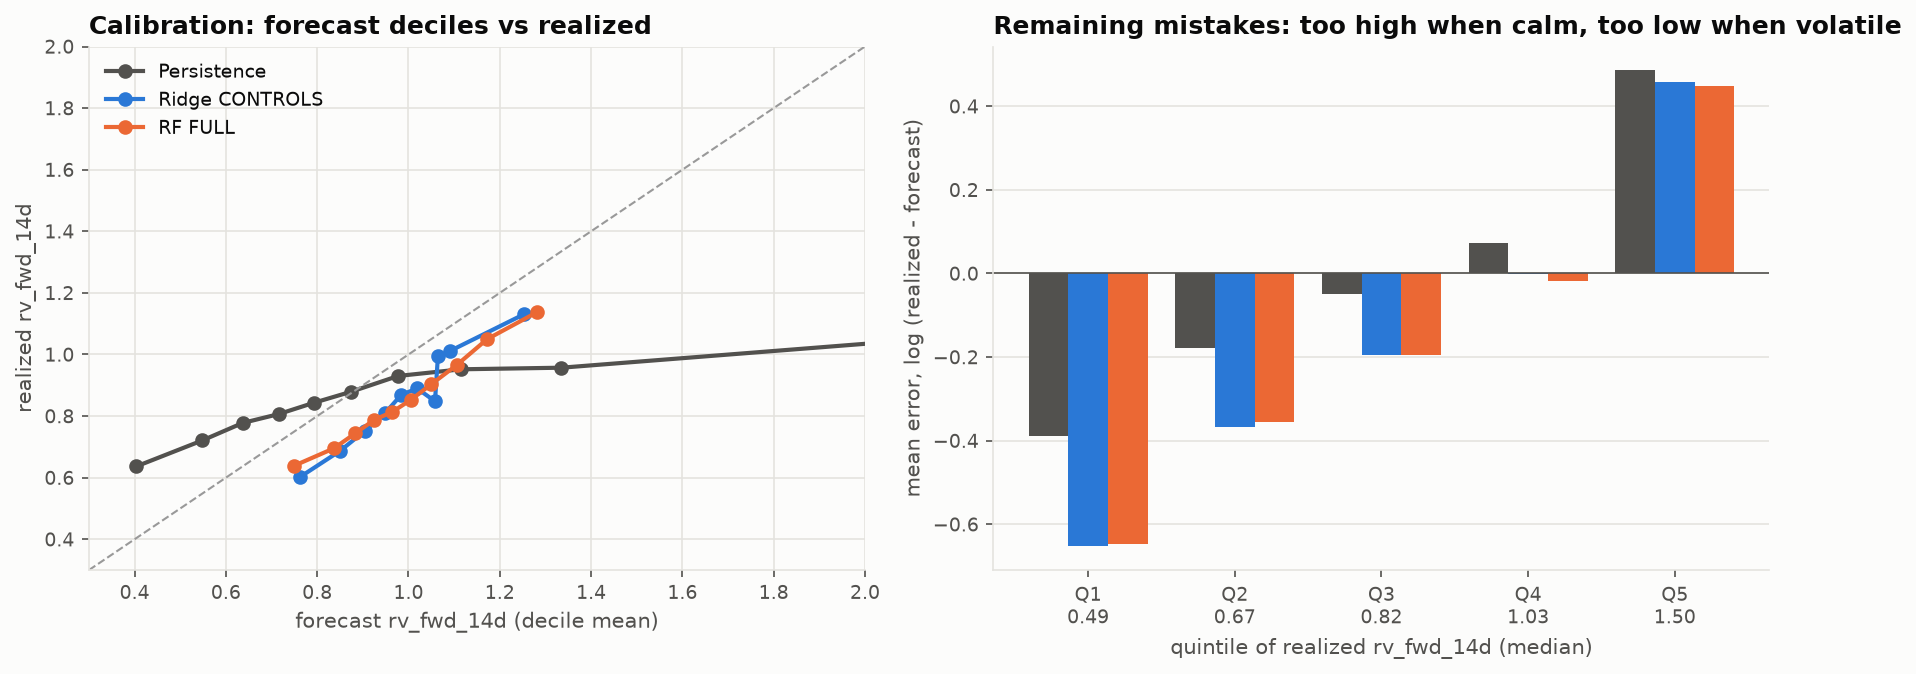

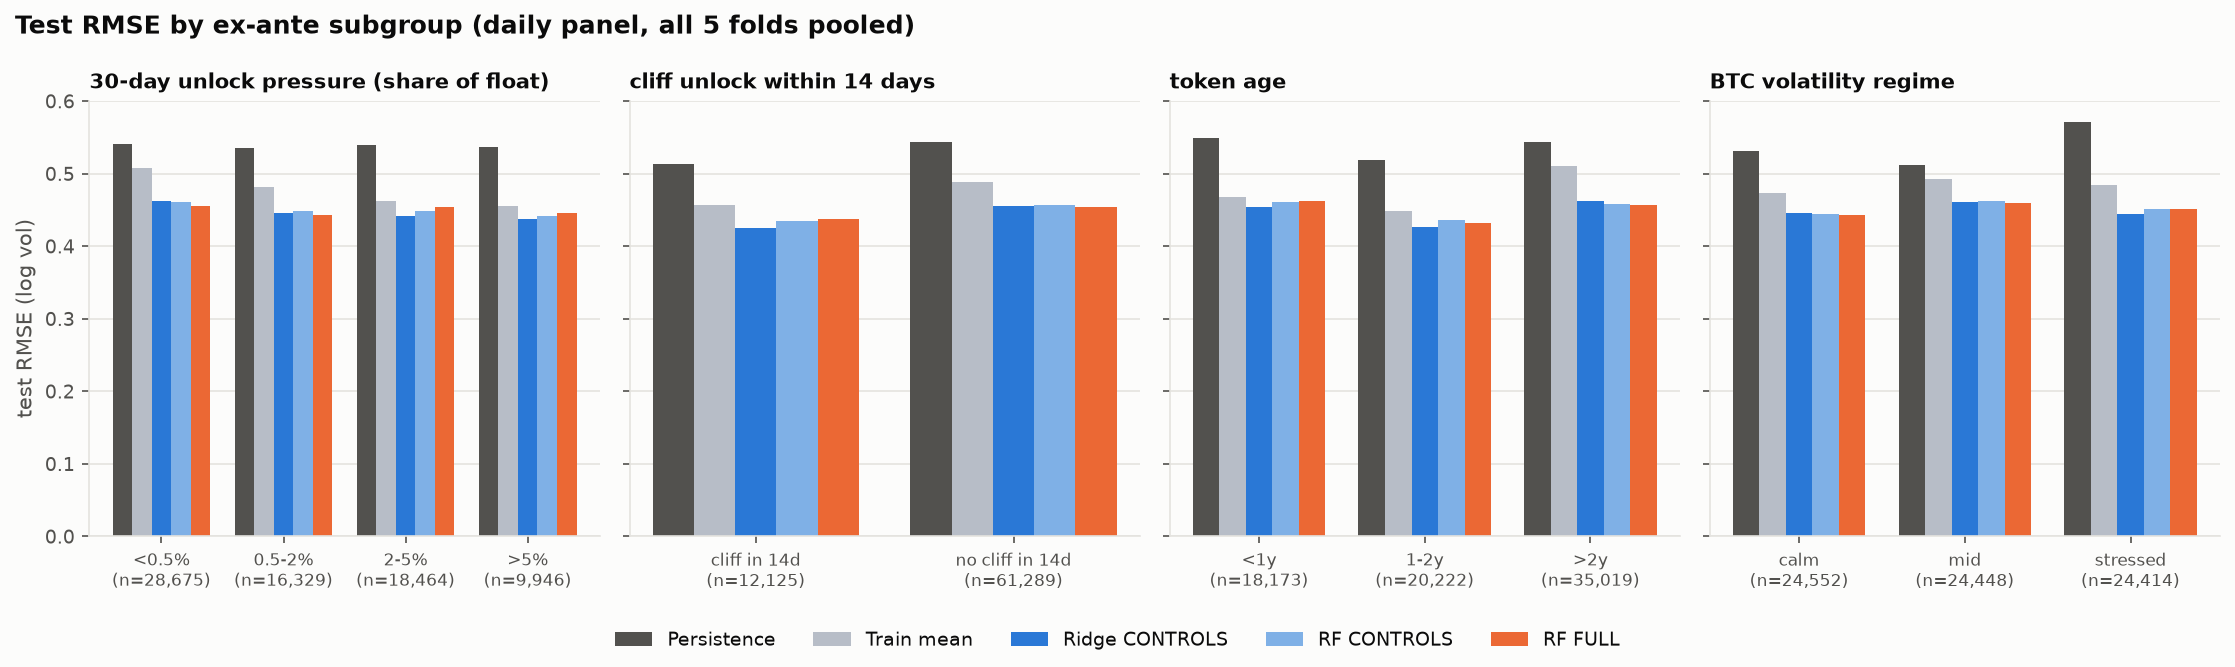

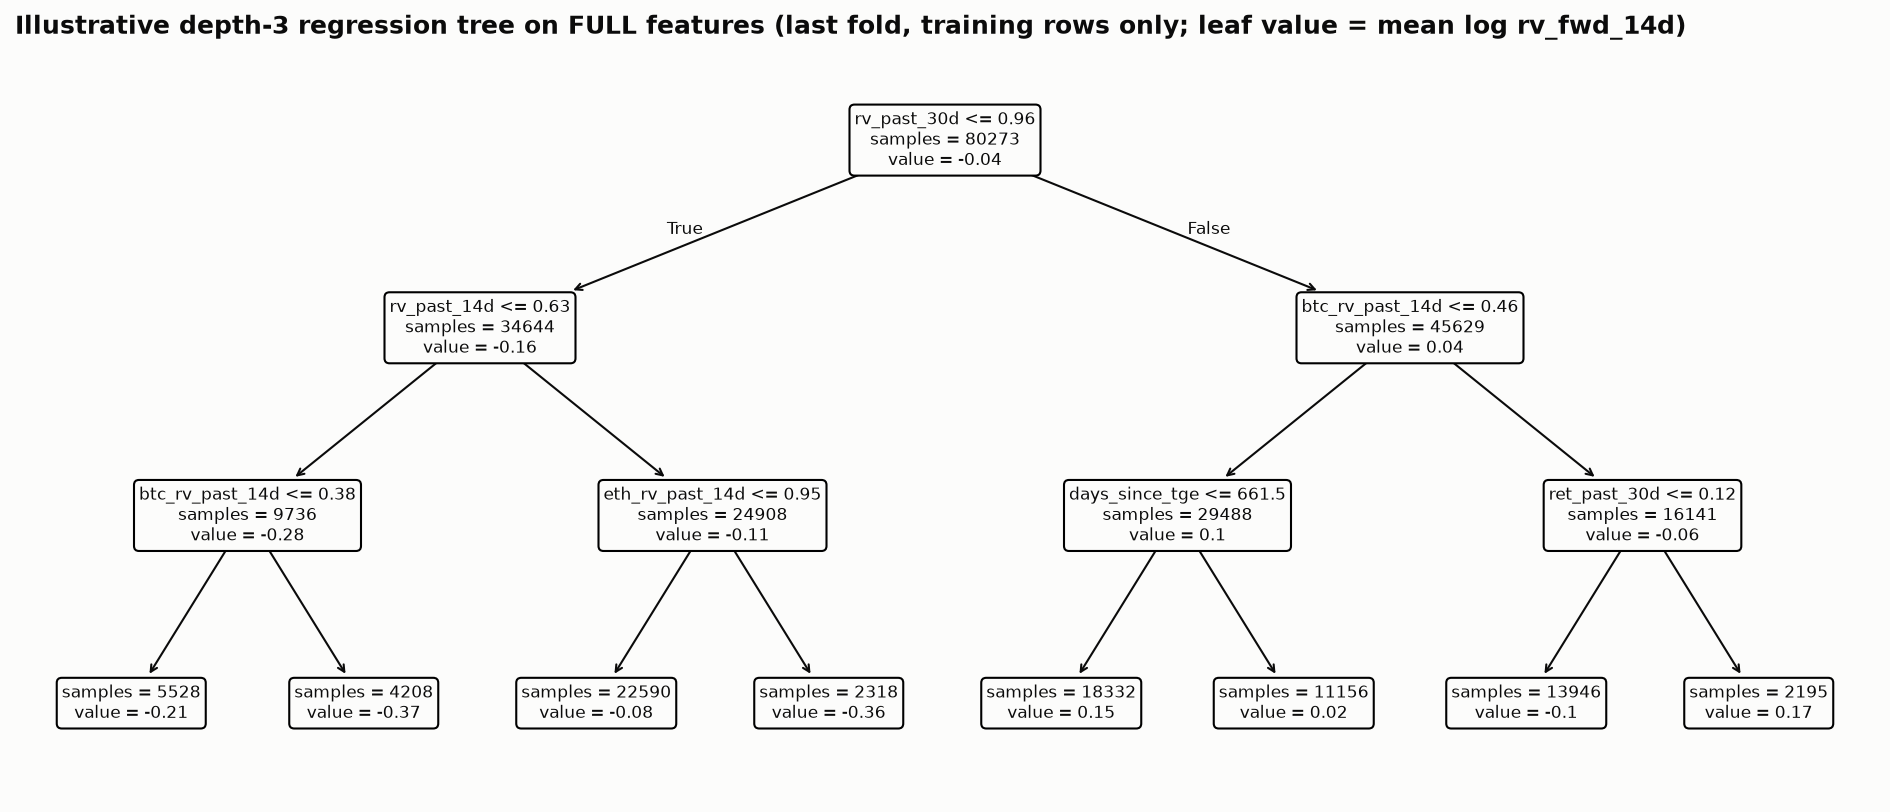

In [30]:
t_err = test_frame(daily, folds_daily)
print(f"{len(t_err):,} test rows, {t_err.token_id.nunique()} tokens; every forecast scored on the same rows")
g_err = group_table(t_err)
lv_err = level_summary(t_err)
bm_err = big_misses(t_err)
if not SMOKE:
    g_err.to_csv(RESULTS_DIR / "error_by_group.csv", index=False)
    lv_err.to_csv(RESULTS_DIR / "error_level_summary.csv", index=False)
    bm_err.to_csv(RESULTS_DIR / "error_big_misses.csv", index=False)
show_cols = ["dimension", "group", "n"] + [f"rmse|{s}" for s in SHOW] + ["delta_rmse|Ridge", "delta_rmse|RF", "delta_rmse|LGBM"]
print("Test RMSE by subgroup; delta = FULL minus CONTROLS (negative = unlock features help)")
display(g_err[show_cols].round(4))
print("Errors in volatility units")
display(lv_err.round(3))
print("Rows the best model (Ridge CONTROLS) misses by more than 2x, against all other rows")
display(bm_err.round(3))
plot_calibration(t_err)
plot_groups(g_err)
tree_used = plot_tree_last_fold(daily, folds_daily)
print("depth-3 tree splits on:", ", ".join(dict.fromkeys(tree_used)))
for f in ["errors_calibration.png", "errors_by_group.png", "tree_depth3_full.png"]:
    display(Image(filename=str(FIGURES_DIR / f)))

## 11. Conclusions

**Answer: no reliable incremental forecasting power.** Adding the 13 emission and 10 static features to the 9 controls moves the mean out-of-sample R2 against persistence by a few thousandths, in either direction depending on the model and the panel frequency, while the fold-to-fold standard deviation of the same metric is 0.15 to 0.21. Both models do beat the persistence forecast comfortably, and beat the pooled train-mean baseline (r2_oos 0.17), but that gain comes from the controls: trailing realized volatility (30d, 14d, 7d), trailing 30-day return and token age are the five most important features by permutation on the last fold's test set, each worth 2 to 5 times more RMSE than the best emission feature (`emis_next_90d_pct_float`). The improvement from emission + static is also not stable in time: for the Random Forest the per-fold delta is +0.031 and +0.031 on the first two folds and -0.017, -0.010 and -0.002 on the last three (daily panel); KNN shows the same sign pattern with larger swings. A feature block that helps only in the oldest folds and hurts in the most recent ones is what a chance result looks like, not a signal.

| model, panel | r2_oos CONTROLS | r2_oos FULL | delta | RMSE CONTROLS | RMSE FULL |
|---|---|---|---|---|---|
| RF, daily | 0.262 | 0.268 | +0.006 | 0.4451 | 0.4431 |
| RF, weekly | 0.234 | 0.241 | +0.007 | 0.4510 | 0.4500 |
| KNN, daily | 0.234 | 0.235 | +0.001 | 0.4526 | 0.4538 |
| KNN, weekly | 0.232 | 0.225 | -0.008 | 0.4534 | 0.4576 |
| RF, daily, INTERNAL tokens only | 0.260 | 0.276 | +0.017 | 0.4416 | 0.4371 |

Robustness runs do not change the reading. KNN is actually best on `CONTROLS+EMIS5` (0.240 daily, 0.239 weekly), a reminder that for a distance-based learner 23 extra noisy dimensions dilute the neighbourhood rather than inform it, and that its FULL result degrades on the weekly panel. The hand-curated `INTERNAL` subsample gives the largest FULL-minus-CONTROLS gap (+0.017), consistent with cleaner schedules carrying slightly more information, but it is still an order of magnitude inside the fold spread. The RF FULL model generalises to the alternative targets (r2_oos 0.35 Parkinson 14d, 0.23 7d, 0.39 30d), which says the harness and the controls are sound, not that the unlock features are. The partial-dependence plot of the FULL model on 30-day unlock pressure is nearly flat across BTC volatility regimes, and removing the aggregate 30-day column does not make the recipient-split columns pick up the slack (test RMSE 0.5088 vs 0.5083).

Two caveats bound this conclusion. The panel covers a single calm-to-moderate volatility regime (2024-09 to 2026-08, no 2020/2022-style stress), so it cannot say how unlocks behave when liquidity is thin. And the schedules are the version curated on the pull date (2026-09-14): they are lookahead-safe mechanically, but a token whose schedule was later revised is scored against the revised version, which can only make the emission features look better than they would have in real time. Under both caveats the honest statement is that, once trailing volatility and market regime are controlled for, scheduled token unlocks do not add forecasting power for 14-day forward realized volatility in this panel. A null result is a valid result; nothing was tuned to change it.


**Linear models and the error analysis (sections 7 and 10).** Ridge and Elastic Net agree: Ridge on controls alone has the best RMSE and rank correlation of all models, adding the unlock features moves its mean r2_oos by +0.001, validation picks heavy shrinkage (alpha 1e4 to 1e7) and Elastic Net sets every coefficient to zero in two of five folds. The error analysis is the most direct test: in the test rows where more than 5% of the float unlocks within 30 days, and where a cliff unlock is less than 14 days away, FULL is *worse* than CONTROLS for both Ridge and the Random Forest, and LightGBM gains nothing there (+0.000 RMSE above 5% unlock). The errors that remain are regression to the mean (forecasts too high for tokens that turn calm, too low for tokens that spike), and none of the unlock features fixes them.